# DualVision AI — Intelligent Digit and Object Recognition
## Homework 5 — Building a Model
**Student:** [Your name] · **Student ID:** [Your ID]  
**Course:** [Course name] · **Instructor:** [Instructor name] · **Submission date:** [Date]

**Submission status:** Real experiments complete. Fill in student/course details before submitting.

Measured held-out test accuracy: **DigitNet 99.25%**, **VisionNet 90.92%** (10,000 test images each). Both models were trained from scratch; test scores were not used for selection.


## 1. Abstract
Two custom PyTorch convolutional networks were trained from scratch on MNIST and CIFAR-10. A stratified training-only validation split selected checkpoints; the official test partitions were evaluated after selection. The report includes loss and accuracy curves, confusion matrices, macro/per-class metrics, observed mistakes, and independently checked Grad-CAM calculations. The notebook embeds selected weights and measured artifacts, and supports CPU inference without retraining or dataset downloads.

Measured held-out test accuracy: **DigitNet 99.25%**, **VisionNet 90.92%** (10,000 test images each). Both models were trained from scratch; test scores were not used for selection.


## 2. Introduction to computer vision and CNNs
Image recognition maps pixel arrays to discrete labels. Convolution shares local filters over an image, building representations from edges and textures to shapes. ReLU introduces nonlinearity; pooling or strided convolution reduces spatial size. Batch normalization stabilizes feature scales and dropout regularizes the classifier. Residual connections help gradients pass through deeper networks.

Both models minimize multiclass cross-entropy on logits:
\[
\mathcal{L}=-\frac{1}{N}\sum_{i=1}^{N}\log\frac{\exp(z_{i,y_i})}{\sum_{c=1}^{10}\exp(z_{i,c})}.
\]
Softmax is applied only for inference probabilities. Test accuracy is the total number of correct predictions divided by the total test count, not an unweighted mean of batch accuracies.


## 3. Project objectives
1. Implement and verify two original CNNs using official torchvision datasets.
2. Separate training, validation and final test evaluation; record reproducible settings.
3. Analyze actual errors and report macro and per-class metrics.
4. Provide portable notebook-local inference, uploads and Grad-CAM.
5. Respect a 4 GB GPU and bounded experiment duration.


## 4. Dataset descriptions
| Dataset | Input | Official training | Training subset | Validation | Held-out test | Classes |
|---|---|---:|---:|---:|---:|---|
| MNIST | 1 × 28 × 28 | 60,000 | 54,000 | 6,000 | 10,000 | Digits 0–9 |
| CIFAR-10 | 3 × 32 × 32 | 50,000 | 45,000 | 5,000 | 10,000 | airplane, automobile, bird, cat, deer, dog, frog, horse, ship, truck |

Validation uses a stratified 10% split from the official training partition with seed 42. Per-channel population mean and standard deviation are measured **only on the selected training subset**, before augmentation. The same values normalize validation, test and uploads. CIFAR-10 training uses random crops with four-pixel padding and horizontal flips; validation/test preprocessing is deterministic. The test partition is never used by training, scheduling or checkpoint selection.


## Environment and execution controls
Use **Python 3.12** and select the project environment as the notebook kernel. For your teacher's **CPU-only laptop**, install:

```powershell
python -m pip install torch==2.8.0 torchvision==0.23.0 --index-url https://download.pytorch.org/whl/cpu
python -m pip install numpy==2.2.6 pandas==2.2.3 matplotlib==3.10.3 scikit-learn==1.6.1 Pillow==11.2.1 jupyterlab==4.4.3 ipywidgets==8.1.7 ipykernel==6.29.5 nbformat==5.10.4 nbclient==0.10.2 pytest==8.3.5
```

The final notebook embeds compact trained checkpoints, saved test metrics, figures and demonstration images. Run all cells in a fresh writable folder: they restore and verify these assets, load weights on CPU when CUDA is absent, and display the measured report **without downloading datasets or retraining**. Inference on uploads still executes the real trained model. For the original GPU training workstation, use the same PyTorch pair from the `cu126` index instead of `cpu`; `nvidia-smi` reports driver support, not Toolkit installation. A broken CUDA operation raises an error instead of silently claiming acceleration.

Run all cells in order. The full implementation below needs no `src/` imports or hidden training script. By default existing compatible checkpoints load and missing models stay pending. For a new real experiment, explicitly set `ALLOW_TRAINING=True` and `DOWNLOAD_DATA=True` after approving downloads and runtime. For another training run use a **new** `EXPERIMENT_ID` and set `RETRAIN=True`; existing checkpoints are never overwritten by retraining. Keep the baseline settings fixed before examining test results.

Default maximums: DigitNet 15 epochs / 30 minutes; VisionNet 50 epochs / 115 minutes. Five additional minutes of the approved 120-minute CIFAR-10 allowance were reserved for an interrupted preliminary attempt; the final run starts afresh with seed 42. Real GPU training checks the time budget at batch boundaries, samples telemetry every five seconds, and stops at the project's conservative 85°C or 95% device-memory policy. These are project safeguards, not manufacturer-rated limits. It preserves the validation-best checkpoint and interrupted state on a safety stop. Early stopping may end sooner. Float32 training and batches of 128/64 avoid mixed-precision assumptions about the T1000. Workers are zero for Windows notebook reliability. Reduce the batch size in a new validation experiment if another application consumes VRAM.


In [1]:
import os
from pathlib import Path

# These defaults never start real-data training or dataset downloads.
ALLOW_TRAINING = False
DOWNLOAD_DATA = False
RETRAIN = False
EXPERIMENT_ID = "baseline"
DEVICE_PREFERENCE = os.environ.get("DUALVISION_DEVICE", "auto")  # CPU portability is explicitly verified
SEED = 42
# The smoke runner sets these environment variables in its child process only.
SMOKE_TEST = os.environ.get("DUALVISION_SMOKE", "0") == "1"
PROJECT_ROOT = Path(os.environ.get("DUALVISION_ROOT", ".")).resolve()
if SMOKE_TEST:
    EXPERIMENT_ID = "notebook-smoke"
    print("SYNTHETIC SMOKE TEST: all displayed scores are software checks, NOT MNIST/CIFAR-10 results.")


In [2]:
"""Restore compact, checksum-verified report/checkpoint assets from the notebook."""
import base64
import hashlib
import io
import json
from pathlib import Path, PurePosixPath
import zipfile


def restore_submission_assets(encoded_archive: str, destination: Path) -> None:
    """Restore only declared project assets; refuse traversal and conflicting files."""
    destination = Path(destination).resolve()
    archive_bytes = base64.b64decode(encoded_archive, validate=True)
    with zipfile.ZipFile(io.BytesIO(archive_bytes)) as archive:
        manifest = json.loads(archive.read('manifest.json'))
        if set(archive.namelist()) != set(manifest) | {'manifest.json'}:
            raise ValueError('Unexpected archive entries.')
        for name, digest in manifest.items():
            relative = PurePosixPath(name)
            if relative.is_absolute() or '..' in relative.parts or ':' in name or '\\' in name:
                raise ValueError('Invalid submission asset path.')
            if not (name.startswith('checkpoints/baseline/') or name.startswith('results/baseline/')):
                raise ValueError('Submission archive contains an unrelated path.')
            target = destination.joinpath(*relative.parts).resolve()
            if not target.is_relative_to(destination):
                raise ValueError('Submission asset escapes the working directory.')
            content = archive.read(name)
            if hashlib.sha256(content).hexdigest() != digest:
                raise ValueError(f'Corrupt submission asset: {name}')
            if target.exists():
                if hashlib.sha256(target.read_bytes()).hexdigest() != digest:
                    raise ValueError(f'Existing artifact differs: {name}. Open this notebook in a fresh folder.')
                continue
            target.parent.mkdir(parents=True, exist_ok=True)
            target.write_bytes(content)
    print('Verified embedded trained checkpoints and report assets; no dataset download or training is required.')


In [3]:
# Compact trained checkpoints and measured report assets; SHA-256 verified on restore.
SUBMISSION_ARCHIVE_B64 = '...'
if SUBMISSION_ARCHIVE_B64 and not SMOKE_TEST and EXPERIMENT_ID == "baseline":
    restore_submission_assets(SUBMISSION_ARCHIVE_B64, PROJECT_ROOT)


Verified embedded trained checkpoints and report assets; no dataset download or training is required.


In [4]:
"""Reproducibility, device verification and atomic artifact utilities."""
import hashlib
import importlib.metadata
import json
import os
import platform
import random
import time
from pathlib import Path

os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')
os.environ.setdefault('MPLCONFIGDIR', str(Path.cwd() / '.downloads' / 'matplotlib'))
import numpy as np
import torch

IMPLEMENTATION_VERSION = 'dualvision-v1'


def seed_everything(seed: int = 42) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    torch.use_deterministic_algorithms(True)
    torch.set_num_threads(min(4, os.cpu_count() or 1))


def select_device(preference: str = 'auto') -> tuple[torch.device, dict]:
    if preference not in {'auto', 'cpu', 'cuda'}:
        raise ValueError('Device must be auto, cpu, or cuda.')
    if preference == 'cuda' and not torch.cuda.is_available():
        raise RuntimeError('CUDA was requested but is unavailable.')
    device = torch.device('cuda' if preference != 'cpu' and torch.cuda.is_available() else 'cpu')
    # Exercise matrix multiplication, not just device enumeration. Fail visibly if broken.
    x = torch.arange(16, dtype=torch.float32, device=device).reshape(4, 4)
    actual = x @ x.T
    expected = torch.arange(16, dtype=torch.float32).reshape(4, 4)
    torch.testing.assert_close(actual.cpu(), expected @ expected.T)
    if device.type == 'cuda':
        torch.cuda.synchronize()
    record = {
        'python': platform.python_version(), 'platform': platform.platform(),
        'device': str(device), 'cuda_available': torch.cuda.is_available(),
        'torch_cuda_runtime': torch.version.cuda,
        'tensor_operation_verified': True,
        'gpu': torch.cuda.get_device_name(0) if device.type == 'cuda' else None,
        'gpu_capability': list(torch.cuda.get_device_capability(0)) if device.type == 'cuda' else None,
        'compiled_cuda_architectures': torch.cuda.get_arch_list() if device.type == 'cuda' else [],
        'gpu_memory_bytes': torch.cuda.get_device_properties(0).total_memory if device.type == 'cuda' else None,
        'versions': {p: importlib.metadata.version(p) for p in
                     ['torch', 'torchvision', 'numpy', 'scikit-learn', 'matplotlib', 'Pillow']},
        'deterministic_algorithms': torch.are_deterministic_algorithms_enabled(),
        'cudnn_benchmark': torch.backends.cudnn.benchmark,
        'cpu_threads': torch.get_num_threads(),
    }
    return device, record


def write_json(path: Path, value: dict | list) -> None:
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix + '.tmp')
    temporary.write_text(json.dumps(value, indent=2, allow_nan=False), encoding='utf-8')
    temporary.replace(path)


def file_sha256(path: Path) -> str:
    digest = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()


def parameter_count(model: torch.nn.Module) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


In [5]:
seed_everything(SEED)
DEVICE, RUNTIME = select_device(DEVICE_PREFERENCE)
print(json.dumps(RUNTIME, indent=2))
print("GPU tensor computation verified" if DEVICE.type == "cuda" else "CPU tensor computation verified")


{
  "python": "3.12.11",
  "platform": "Windows-11-10.0.26300-SP0",
  "device": "cpu",
  "cuda_available": false,
  "torch_cuda_runtime": "12.6",
  "tensor_operation_verified": true,
  "gpu": null,
  "gpu_capability": null,
  "compiled_cuda_architectures": [],
  "gpu_memory_bytes": null,
  "versions": {
    "torch": "2.8.0+cu126",
    "torchvision": "0.23.0+cu126",
    "numpy": "2.2.6",
    "scikit-learn": "1.6.1",
    "matplotlib": "3.10.3",
    "Pillow": "11.2.1"
  },
  "deterministic_algorithms": true,
  "cudnn_benchmark": false,
  "cpu_threads": 4
}
CPU tensor computation verified


## 5. MNIST methodology
DigitNet has two 3×3 convolutional stages (32 and 64 channels), each with batch normalization, ReLU and 2×2 max-pooling. Dropout2d regularizes features; a 128-unit hidden classifier uses ReLU and dropout before ten logits. This modest architecture retains spatial information needed for handwritten digits. AdamW uses learning rate 0.001 and weight decay 0.0001. A cosine schedule lowers the learning rate; validation accuracy selects the best epoch with validation loss as a tie-breaker. Patience is five epochs.

The next cells also define reusable routines for both experiments. Source-equivalent implementations are included inline to make this notebook independently executable.


## 6. Complete executable MNIST implementation
### Architectures
Both model classes are defined here so shared experiment helpers can instantiate either model. VisionNet's methodology is explained in Section 8.


In [6]:
"""Two independently trained custom classifiers; no pretrained weights."""
import torch
from torch import nn


class DigitNet(nn.Module):
    """Compact 28x28 grayscale CNN with a 128-unit classification head."""
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1, bias=False), nn.BatchNorm2d(32), nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1, bias=False), nn.BatchNorm2d(64), nn.ReLU(),
            nn.MaxPool2d(2), nn.Dropout2d(0.15),
        )
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(64 * 7 * 7, 128),
                                        nn.ReLU(), nn.Dropout(0.4), nn.Linear(128, 10))

    def forward(self, x):
        return self.classifier(self.features(x))


class ResidualBlock(nn.Module):
    def __init__(self, in_channels: int, out_channels: int, stride: int = 1):
        super().__init__()
        self.body = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, stride, 1, bias=False),
            nn.BatchNorm2d(out_channels), nn.ReLU(),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
        )
        self.skip = nn.Identity() if stride == 1 and in_channels == out_channels else nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 1, stride, bias=False), nn.BatchNorm2d(out_channels))
        self.activation = nn.ReLU()

    def forward(self, x):
        return self.activation(self.body(x) + self.skip(x))


class VisionNet(nn.Module):
    """Narrow residual CNN for 32x32 RGB images and 4 GB GPUs."""
    def __init__(self):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, 32, 3, padding=1, bias=False),
                                  nn.BatchNorm2d(32), nn.ReLU())
        self.stage1 = nn.Sequential(ResidualBlock(32, 32), ResidualBlock(32, 32))
        self.stage2 = nn.Sequential(ResidualBlock(32, 64, 2), ResidualBlock(64, 64))
        self.stage3 = nn.Sequential(ResidualBlock(64, 128, 2), ResidualBlock(128, 128))
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.head = nn.Sequential(nn.Flatten(), nn.Dropout(0.25), nn.Linear(128, 10))

    def forward(self, x):
        x = self.stage3(self.stage2(self.stage1(self.stem(x))))
        return self.head(self.pool(x))


def make_model(dataset: str) -> nn.Module:
    if dataset == 'mnist':
        return DigitNet()
    if dataset == 'cifar10':
        return VisionNet()
    raise ValueError(f'Unknown dataset: {dataset}')


### Data partitions and preprocessing
Official partition sizes and class ordering are checked. Split indices and their SHA-256 fingerprint are recorded with each experiment. Synthetic smoke mode uses disjoint FakeData offsets and writes to a separate directory.


In [7]:
"""Official partitions, stratified validation, and training-only statistics."""
import hashlib
from dataclasses import dataclass
from pathlib import Path

import numpy as np
import torch
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

CIFAR_CLASSES = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


@dataclass
class DataBundle:
    train: DataLoader
    validation: DataLoader
    test: DataLoader
    classes: list[str]
    mean: list[float]
    std: list[float]
    metadata: dict


def split_indices(targets, seed: int = 42):
    indices = np.arange(len(targets))
    train_idx, val_idx = train_test_split(indices, test_size=0.1, random_state=seed, stratify=np.asarray(targets))
    assert not np.intersect1d(train_idx, val_idx).size
    assert len(train_idx) + len(val_idx) == len(targets)
    return train_idx, val_idx


def channel_statistics(raw_data, indices, grayscale: bool) -> tuple[list, list]:
    """Population channel moments computed only on the selected training subset."""
    raw = np.asarray(raw_data)
    total = np.zeros(1 if grayscale else 3, dtype=np.float64)
    square = np.zeros_like(total)
    count = 0
    for start in range(0, len(indices), 512):
        pixels = raw[indices[start:start + 512]].astype(np.float64) / 255.0
        if grayscale:
            pixels = pixels[..., None]
        pixels = pixels.reshape(-1, pixels.shape[-1])
        total += pixels.sum(axis=0)
        square += np.square(pixels).sum(axis=0)
        count += len(pixels)
    mean = total / count
    std = np.sqrt(np.maximum(square / count - mean ** 2, 1e-12))
    return mean.tolist(), std.tolist()


def image_transform(dataset: str, mean, std, training: bool = False):
    ops = []
    if dataset == 'cifar10' and training:
        ops.extend([transforms.RandomCrop(32, padding=4), transforms.RandomHorizontalFlip()])
    ops.extend([transforms.ToTensor(), transforms.Normalize(mean, std)])
    return transforms.Compose(ops)


def prepare_data(dataset: str, root: Path, batch_size: int, seed: int = 42,
                 download: bool = False, smoke: bool = False, pin_memory: bool = False) -> DataBundle:
    if dataset not in {'mnist', 'cifar10'}:
        raise ValueError(dataset)
    grayscale = dataset == 'mnist'
    classes = [str(i) for i in range(10)] if grayscale else CIFAR_CLASSES
    if smoke:
        # Synthetic data checks plumbing only. It never produces benchmark evidence.
        mean, std = ([0.5], [0.25]) if grayscale else ([0.5] * 3, [0.25] * 3)
        shape = (1, 28, 28) if grayscale else (3, 32, 32)
        parts = [datasets.FakeData(n, shape, 10, transform=image_transform(dataset, mean, std, i == 0),
                                  random_offset=seed + i * 1000) for i, n in enumerate([32, 16, 20])]
        metadata = {'source': 'SYNTHETIC_SMOKE_ONLY', 'split_seed': seed,
                    'sizes': [32, 16, 20], 'split_sha256': 'synthetic-disjoint-offsets'}
    else:
        constructor = datasets.MNIST if grayscale else datasets.CIFAR10
        raw = constructor(root=str(root), train=True, download=download)
        expected_train = 60000 if grayscale else 50000
        if len(raw) != expected_train:
            raise ValueError('Unexpected official training partition size.')
        train_idx, val_idx = split_indices(raw.targets, seed)
        mean, std = channel_statistics(raw.data, train_idx, grayscale)
        training = constructor(root=str(root), train=True, download=False,
                               transform=image_transform(dataset, mean, std, True))
        validation = constructor(root=str(root), train=True, download=False,
                                 transform=image_transform(dataset, mean, std, False))
        test = constructor(root=str(root), train=False, download=download,
                           transform=image_transform(dataset, mean, std, False))
        if len(test) != 10000:
            raise ValueError('Unexpected official test partition size.')
        if not grayscale and list(raw.classes) != CIFAR_CLASSES:
            raise ValueError('Unexpected CIFAR-10 class order.')
        parts = [Subset(training, train_idx.tolist()), Subset(validation, val_idx.tolist()), test]
        metadata = {'source': 'torchvision-official', 'split_seed': seed,
                    'sizes': [len(p) for p in parts],
                    'split_sha256': hashlib.sha256(train_idx.astype('<i8').tobytes() + val_idx.astype('<i8').tobytes()).hexdigest(),
                    'train_indices': train_idx.tolist(), 'validation_indices': val_idx.tolist(),
                    'statistics_source': 'training-subset-only'}
    # num_workers=0 is deliberate: portable in Windows notebooks, deterministic and modest RAM use.
    loaders = [DataLoader(part, batch_size=batch_size, shuffle=i == 0, num_workers=0,
                          pin_memory=pin_memory, generator=torch.Generator().manual_seed(seed + i))
               for i, part in enumerate(parts)]
    return DataBundle(*loaders, classes, mean, std, metadata)


### Training, mini-batch verification and checkpointing
Training and validation explicitly use `train()` and `eval()`; validation disables gradients. Loss is weighted by batch sample count. Mini-batch checks use a disposable model; RNG and loader shuffle state are reset before actual training. Checkpoints store CPU `state_dict` tensors and metadata; loading uses `weights_only=True`, strict architecture matching and experiment metadata checks. Atomic recovery snapshots save optimizer, scheduler and random streams after each complete epoch. Explicit resumption stays within the cumulative time budget. Legacy best-weight-only recovery restarts optimizer moments and is recorded as a methodological limitation. An interrupted training run is not eligible for test evaluation until bounded training is finalized.


In [8]:
"""Sample NVIDIA telemetry and stop conservatively on thermal/hardware faults."""
import csv
import json
import subprocess
import time
from pathlib import Path


class HardwareStop(RuntimeError):
    """Training must stop and preserve its current state."""


class TrainingBudgetExceeded(RuntimeError):
    """The wall-clock training budget expired at a batch boundary."""


class TrainingGuard:
    def __init__(self, log_path, max_minutes, max_temperature=85, interval=5.0, elapsed_offset=0.0):
        self.log_path = Path(log_path)
        self.log_path.parent.mkdir(parents=True, exist_ok=True)
        self.started = time.monotonic()
        self.deadline = self.started + max_minutes * 60
        self.max_temperature = max_temperature  # conservative project policy, not a rated hardware limit
        self.interval = interval
        self.last_sample = float('-inf')
        self.samples = 0
        self.peak_temperature = 0
        self.peak_used_mib = 0
        self.elapsed_offset = elapsed_offset
        if elapsed_offset and self.log_path.exists():
            for line in self.log_path.read_text(encoding='utf-8').splitlines():
                previous = json.loads(line)
                self.samples += 1
                self.peak_temperature = max(self.peak_temperature, previous['temperature_c'])
                self.peak_used_mib = max(self.peak_used_mib, previous['memory_used_mib'])

    def check(self, force=False):
        now = time.monotonic()
        if now >= self.deadline:
            raise TrainingBudgetExceeded('Training wall-clock budget reached.')
        if not force and now - self.last_sample < self.interval:
            return
        self.last_sample = now
        try:
            output = subprocess.check_output([
                'nvidia-smi', '--id=0',
                '--query-gpu=temperature.gpu,memory.used,memory.total,utilization.gpu,power.draw',
                '--format=csv,noheader,nounits'], text=True, timeout=10,
                creationflags=getattr(subprocess, 'CREATE_NO_WINDOW', 0))
            fields = next(csv.reader(output.strip().splitlines()))
            temperature, used, total, utilization, power = map(float, fields)
        except (OSError, subprocess.SubprocessError, ValueError, StopIteration) as error:
            raise HardwareStop(f'GPU telemetry unavailable: {error}') from error
        record = {'elapsed_seconds': self.elapsed_offset + now - self.started, 'temperature_c': temperature,
                  'memory_used_mib': used, 'memory_total_mib': total,
                  'gpu_utilization_percent': utilization, 'power_w': power}
        with self.log_path.open('a', encoding='utf-8') as handle:
            handle.write(json.dumps(record) + '\n')
        self.samples += 1
        self.peak_temperature = max(self.peak_temperature, temperature)
        self.peak_used_mib = max(self.peak_used_mib, used)
        if temperature >= self.max_temperature:
            raise HardwareStop(f'GPU reached {temperature:.0f} C; project stop threshold is {self.max_temperature} C.')
        if used >= total * 0.95:
            raise HardwareStop(f'GPU memory pressure: {used:.0f}/{total:.0f} MiB used (95% stop policy).')

    def summary(self):
        return {'sample_interval_seconds': self.interval, 'sample_count': self.samples,
                'temperature_stop_c': self.max_temperature, 'memory_stop_fraction': 0.95,
                'peak_temperature_c': self.peak_temperature, 'peak_device_memory_used_mib': self.peak_used_mib}


In [9]:
"""Training, early stopping and strict state_dict checkpoints."""
import copy
import json
import math
import random
import time
from pathlib import Path

import numpy as np
import torch
from torch import nn


def epoch_pass(model, loader, device, optimizer=None, guard=None) -> dict:
    training = optimizer is not None
    model.train(training)
    total_loss, correct, count = 0.0, 0, 0
    context = torch.enable_grad() if training else torch.inference_mode()
    with context:
        for images, labels in loader:
            if guard is not None:
                guard.check()
            images, labels = images.to(device), labels.to(device)
            if training:
                optimizer.zero_grad(set_to_none=True)
            logits = model(images)
            loss = nn.functional.cross_entropy(logits, labels)
            if not torch.isfinite(loss):
                raise FloatingPointError('Non-finite loss; experiment aborted.')
            if training:
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
                optimizer.step()
            count += labels.numel()
            total_loss += loss.item() * labels.numel()
            correct += int((logits.argmax(1) == labels).sum().item())
    if count == 0:
        raise ValueError('Empty data loader.')
    return {'loss': total_loss / count, 'accuracy': correct / count, 'count': count}


def save_checkpoint(path: Path, model, metadata: dict) -> None:
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix('.tmp')
    state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}
    torch.save({'schema': 1, 'state_dict': state, 'metadata': metadata}, temporary)
    temporary.replace(path)


def load_checkpoint(path: Path, model, device, expected: dict | None = None) -> dict:
    payload = torch.load(path, map_location='cpu', weights_only=True)
    if payload.get('schema') != 1 or not isinstance(payload.get('metadata'), dict):
        raise ValueError('Unsupported checkpoint format.')
    meta = payload['metadata']
    if meta.get('implementation') != IMPLEMENTATION_VERSION:
        raise ValueError('Checkpoint implementation version mismatch; use a new experiment directory.')
    for key, value in (expected or {}).items():
        if meta.get(key) != value:
            raise ValueError(f'Checkpoint metadata mismatch: {key}')
    model.load_state_dict(payload['state_dict'], strict=True)
    model.to(device).eval()
    return meta


def mini_batch_check(model, loader, device) -> None:
    """Test a disposable copy, preserving the initialization for the real experiment."""
    candidate = copy.deepcopy(model).to(device)
    images, labels = next(iter(loader))
    images, labels = images.to(device), labels.to(device)
    candidate.train()
    optimizer = torch.optim.AdamW(candidate.parameters(), lr=1e-3)
    optimizer.zero_grad(set_to_none=True)
    logits = candidate(images)
    assert logits.shape == (len(labels), 10)
    loss = nn.functional.cross_entropy(logits, labels)
    assert torch.isfinite(loss)
    loss.backward()
    optimizer.step()
    del candidate, optimizer


def fit(model, bundle, device, config: dict, checkpoint_path: Path, metadata: dict, resume=False) -> dict:
    """Select by validation accuracy, breaking ties with lower validation loss."""
    if config['epochs'] < 1 or config['patience'] < 1 or config['max_minutes'] <= 0:
        raise ValueError('Epochs, patience and time budget must be positive.')
    model.to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=config['lr'], weight_decay=config['weight_decay'])
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=config['epochs'])
    history, best_key, bad_epochs = [], (-1.0, float('-inf')), 0
    prior_seconds, first_epoch = 0.0, 1
    best_metadata = None
    resume_path = checkpoint_path.parent / 'resume.pt'
    if resume:
        best_metadata = load_checkpoint(checkpoint_path, model, device, {'dataset': metadata['dataset']})
        if best_metadata.get('training_status') == 'complete':
            raise ValueError('A completed experiment must not be resumed after test evaluation.')
        if resume_path.exists():
            state = torch.load(resume_path, map_location='cpu', weights_only=True)
            assert state['config'] == config and state['dataset'] == metadata['dataset']
            model.load_state_dict(state['state_dict'])
            optimizer.load_state_dict(state['optimizer'])
            scheduler.load_state_dict(state['scheduler'])
            history, bad_epochs = state['history'], state['bad_epochs']
            prior_seconds = state['training_seconds']
            torch.set_rng_state(state['torch_rng'])
            if device.type == 'cuda':
                torch.cuda.set_rng_state_all(state['cuda_rng'])
            bundle.train.generator.set_state(state['loader_rng'])
            random.setstate(state['python_rng'])
            np_state = state['numpy_rng']
            np.random.set_state((np_state[0], np.asarray(np_state[1], dtype=np.uint32), *np_state[2:]))
            metadata = state['metadata']
            telemetry_path = checkpoint_path.parent / 'gpu_telemetry.jsonl'
            if telemetry_path.exists():
                samples = [json.loads(line) for line in telemetry_path.read_text().splitlines()]
                prior_seconds = max(prior_seconds, max(row['elapsed_seconds'] for row in samples)) + 5.0
            print(f'Resuming complete optimizer/RNG state after epoch {history[-1]["epoch"]}.', flush=True)
        else:
            # Legacy best-only checkpoints cannot recover AdamW momentum or the exact RNG stream.
            history = list(best_metadata['history'])
            prior_seconds = sum(row['seconds'] for row in history)
            telemetry_path = checkpoint_path.parent / 'gpu_telemetry.jsonl'
            if telemetry_path.exists():
                samples = [json.loads(line) for line in telemetry_path.read_text().splitlines()]
                prior_seconds = max(prior_seconds, max(row['elapsed_seconds'] for row in samples))
            prior_seconds += 5.0  # conservative allowance for unsampled work before interruption
            finished_epoch = history[-1]['epoch']
            # Continue the original cosine schedule, but explicitly restart optimizer moments.
            for group in optimizer.param_groups:
                group['initial_lr'] = config['lr']
                group['lr'] = config['lr'] * (1 + math.cos(math.pi * (finished_epoch - 1) / config['epochs'])) / 2
            scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
                optimizer, T_max=config['epochs'], last_epoch=finished_epoch - 1)
            metadata = {**metadata, 'recovery': {'method': 'best_weights_with_fresh_AdamW_moments_and_reseeded_RNG',
                'after_epoch': finished_epoch, 'prior_seconds_including_5s_allowance': prior_seconds,
                'limitation': 'Not an exact uninterrupted run; original cosine epoch schedule continues.'}}
            metadata['training_duration_note'] = 'Cumulative active training time, including a conservative 5-second interruption allowance; excludes the inactive gap.'
            best_metadata.update(recovery=metadata['recovery'])
            print(f'Recovering weights after epoch {finished_epoch}; optimizer moments restart, documented in metadata.', flush=True)
        first_epoch = history[-1]['epoch'] + 1
        selected = max(history, key=lambda row: (row['validation_accuracy'], -row['validation_loss']))
        best_key = (selected['validation_accuracy'], -selected['validation_loss'])
        bad_epochs = history[-1]['epoch'] - selected['epoch']
        if prior_seconds >= config['max_minutes'] * 60:
            raise RuntimeError('No training budget remains for resumption.')
    if device.type == 'cuda':
        torch.cuda.synchronize()
        torch.cuda.reset_peak_memory_stats()
    started = time.perf_counter()
    stop_reason = 'epoch_limit'
    guard = TrainingGuard(checkpoint_path.parent / 'gpu_telemetry.jsonl', config['max_minutes'] - prior_seconds / 60,
                          elapsed_offset=prior_seconds) if device.type == 'cuda' and not metadata.get('smoke', False) else None
    for epoch in range(first_epoch, config['epochs'] + 1):
        epoch_start = time.perf_counter()
        lr = optimizer.param_groups[0]['lr']
        try:
            if guard is not None:
                train_metrics = epoch_pass(model, bundle.train, device, optimizer, guard=guard)
                validation_metrics = epoch_pass(model, bundle.validation, device, guard=guard)
            else:
                train_metrics = epoch_pass(model, bundle.train, device, optimizer)
                validation_metrics = epoch_pass(model, bundle.validation, device)
        except (RuntimeError, KeyboardInterrupt) as error:
            # Preserve current weights and optimizer state without replacing the best model.
            progress_meta = {**metadata, 'training_status': 'interrupted', 'interrupted_epoch': epoch,
                             'history': history, 'training_seconds': prior_seconds + time.perf_counter() - started,
                             'stop_reason': str(error), 'telemetry': guard.summary() if guard else None}
            progress_path = checkpoint_path.parent / 'interrupted.pt'
            save_checkpoint(progress_path, model, progress_meta)
            optimizer_path = checkpoint_path.parent / 'optimizer_interrupted.pt'
            torch.save({'optimizer': optimizer.state_dict(), 'scheduler': scheduler.state_dict(),
                        'epoch': epoch, 'torch_rng': torch.get_rng_state(),
                        'cuda_rng': torch.cuda.get_rng_state_all() if device.type == 'cuda' else [],
                        'loader_rng': bundle.train.generator.get_state()}, optimizer_path)
            write_json(checkpoint_path.parent / 'interruption.json', progress_meta)
            if isinstance(error, TrainingBudgetExceeded) and best_metadata is not None:
                stop_reason = 'time_budget_at_batch_boundary'
                break
            raise
        scheduler.step()
        if device.type == 'cuda':
            torch.cuda.synchronize()
        row = {'epoch': epoch, 'lr': lr, 'seconds': time.perf_counter() - epoch_start,
               'train_loss': train_metrics['loss'], 'train_accuracy': train_metrics['accuracy'],
               'validation_loss': validation_metrics['loss'], 'validation_accuracy': validation_metrics['accuracy']}
        history.append(row)
        key = (row['validation_accuracy'], -row['validation_loss'])
        if key > best_key:
            best_key, bad_epochs = key, 0
            best_metadata = {**metadata, 'best_epoch': epoch, 'best_validation_accuracy': key[0],
                             'history': list(history), 'training_status': 'in_progress'}
            save_checkpoint(checkpoint_path, model, best_metadata)
        else:
            bad_epochs += 1
        write_json(checkpoint_path.parent / 'history.json', history)
        # Atomic epoch-boundary recovery: weights, AdamW moments, schedule and random streams.
        np_state = np.random.get_state()
        recovery_state = {'state_dict': {key: value.detach().cpu().clone() for key, value in model.state_dict().items()},
            'optimizer': optimizer.state_dict(), 'scheduler': scheduler.state_dict(),
            'history': list(history), 'bad_epochs': bad_epochs, 'config': config, 'dataset': metadata['dataset'],
            'metadata': metadata, 'training_seconds': prior_seconds + time.perf_counter() - started,
            'torch_rng': torch.get_rng_state(), 'cuda_rng': torch.cuda.get_rng_state_all() if device.type == 'cuda' else [],
            'loader_rng': bundle.train.generator.get_state(), 'python_rng': random.getstate(),
            'numpy_rng': (np_state[0], np_state[1].tolist(), *np_state[2:])}
        temporary = resume_path.with_suffix('.tmp')
        torch.save(recovery_state, temporary)
        temporary.replace(resume_path)
        print(f"Epoch {epoch:02d}/{config['epochs']} | train {row['train_accuracy']:.2%} | "
              f"validation {row['validation_accuracy']:.2%} | {row['seconds']:.1f}s", flush=True)
        if bad_epochs >= config['patience']:
            stop_reason = 'early_stopping'
            break
        if prior_seconds + time.perf_counter() - started >= config['max_minutes'] * 60:
            stop_reason = 'time_budget'
            break
    elapsed = prior_seconds + time.perf_counter() - started
    # Reload selected weights; preserve full history even when later epochs were worse.
    load_checkpoint(checkpoint_path, model, device, {'dataset': metadata['dataset']})
    best_metadata.update(history=history, training_status='complete', stop_reason=stop_reason,
                         training_seconds=elapsed,
                         peak_gpu_memory_bytes=torch.cuda.max_memory_allocated() if device.type == 'cuda' else 0)
    if guard is not None:
        best_metadata['telemetry'] = guard.summary()
    save_checkpoint(checkpoint_path, model, best_metadata)
    return best_metadata


### Evaluation and reporting helpers
Final test predictions are cached against the selected checkpoint's SHA-256 hash and reused on reruns. The cache validates its metrics against stored predictions. Precision, recall and F1 are **macro-averaged** across all ten classes (equal class weight); the full report also includes support and weighted averages. Undefined per-class metrics use zero explicitly.


In [10]:
"""Held-out evaluation with checkpoint-bound cached predictions."""
from pathlib import Path

import numpy as np
import torch
from sklearn.metrics import classification_report, confusion_matrix


def load_evaluation(cache, checkpoint, classes, count=10000, source='torchvision-official'):
    """Validate saved benchmark evidence without loading or downloading datasets."""
    import json
    result = json.loads(Path(cache).read_text(encoding='utf-8'))
    if (result['checkpoint_sha256'] != file_sha256(checkpoint) or result['source'] != source
            or result['count'] != count or result['classes'] != classes):
        raise ValueError('Saved evaluation does not match checkpoint, dataset or classes.')
    checked = classification_metrics(result['labels'], result['predictions'], classes)
    for key in ['count', 'accuracy', 'macro_precision', 'macro_recall', 'macro_f1', 'confusion_matrix', 'report']:
        if checked[key] != result[key]:
            raise ValueError(f'Saved evaluation is inconsistent: {key}')
    return result


def classification_metrics(labels, predictions, classes) -> dict:
    labels, predictions = np.asarray(labels), np.asarray(predictions)
    if len(labels) == 0 or labels.shape != predictions.shape:
        raise ValueError('Expected matching nonempty labels and predictions.')
    report = classification_report(labels, predictions, labels=list(range(len(classes))),
                                   target_names=classes, output_dict=True, zero_division=0)
    return {'accuracy': float(np.mean(labels == predictions)), 'count': len(labels),
            'macro_precision': report['macro avg']['precision'],
            'macro_recall': report['macro avg']['recall'], 'macro_f1': report['macro avg']['f1-score'],
            'report': report,
            'confusion_matrix': confusion_matrix(labels, predictions, labels=list(range(len(classes)))).tolist()}


def evaluate_once(model, loader, device, classes, checkpoint: Path, output_dir: Path, source: str):
    """Reuse predictions for the exact selected checkpoint; never select using test scores."""
    import json
    output_dir.mkdir(parents=True, exist_ok=True)
    cache = output_dir / 'evaluation.json'
    fingerprint = file_sha256(checkpoint)
    if cache.exists():
        result = json.loads(cache.read_text(encoding='utf-8'))
        if (result['checkpoint_sha256'] != fingerprint or result['source'] != source
                or result['count'] != len(loader.dataset) or result['classes'] != classes):
            raise ValueError('Stale evaluation cache. Choose a new experiment directory; do not mix runs.')
        checked = classification_metrics(result['labels'], result['predictions'], classes)
        for key in ['accuracy', 'macro_precision', 'macro_recall', 'macro_f1', 'confusion_matrix', 'report']:
            if checked[key] != result[key]:
                raise ValueError(f'Cached evaluation is inconsistent: {key}')
        return result
    labels, predictions, confidence = [], [], []
    loss_sum = 0.0
    model.eval()
    with torch.inference_mode():
        for images, targets in loader:
            images, targets = images.to(device), targets.to(device)
            logits = model(images)
            loss_sum += torch.nn.functional.cross_entropy(logits, targets, reduction='sum').item()
            probabilities = logits.softmax(1)
            values, indices = probabilities.max(1)
            labels.extend(targets.cpu().tolist())
            predictions.extend(indices.cpu().tolist())
            confidence.extend(values.cpu().tolist())
    result = {**classification_metrics(labels, predictions, classes),
              'loss': loss_sum / len(labels), 'classes': classes,
              'labels': labels, 'predictions': predictions, 'confidence': confidence,
              'checkpoint_sha256': fingerprint, 'source': source}
    write_json(cache, result)
    return result


In [11]:
"""Figures and error summaries derived only from recorded predictions/history."""
from pathlib import Path

import matplotlib
# Figures are saved and displayed as notebook PNGs; no desktop GUI/Tk is needed.
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import ConfusionMatrixDisplay


def denormalize(image, mean, std):
    image = image.detach().cpu()
    pixels = image * torch.tensor(std)[:, None, None] + torch.tensor(mean)[:, None, None]
    return pixels.clamp(0, 1).permute(1, 2, 0).numpy().squeeze()


def save_fig(fig, path):
    fig.savefig(path, dpi=150, bbox_inches='tight')
    plt.close(fig)


def make_figures(metadata, evaluation, bundle, output_dir: Path) -> list[Path]:
    output_dir.mkdir(parents=True, exist_ok=True)
    history = pd.DataFrame(metadata['history'])
    paths = []
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for ax, metric in zip(axes, ['loss', 'accuracy']):
        for split in ['train', 'validation']:
            ax.plot(history.epoch, history[f'{split}_{metric}'], marker='o', markersize=3, label=split)
        ax.axvline(metadata['best_epoch'], color='gray', linestyle='--', label='selected epoch')
        ax.set(xlabel='Epoch', ylabel=metric.capitalize(), title=f"{metadata['dataset'].upper()} {metric}")
        ax.legend()
        if len(history) <= 15:
            ax.set_xticks(history.epoch)
        ax.grid(alpha=0.2)
    fig.suptitle('SYNTHETIC SMOKE TEST — NOT BENCHMARK RESULTS' if metadata['smoke'] else 'Learning curves')
    paths.append(output_dir / 'learning_curves.png')
    save_fig(fig, paths[-1])
    fig, ax = plt.subplots(figsize=(8, 7))
    ConfusionMatrixDisplay(np.asarray(evaluation['confusion_matrix']), display_labels=bundle.classes).plot(
        ax=ax, cmap='Blues', colorbar=False, xticks_rotation=45)
    ax.set_title('Synthetic smoke predictions' if metadata['smoke'] else 'Held-out test confusion matrix')
    paths.append(output_dir / 'confusion_matrix.png')
    save_fig(fig, paths[-1])
    truth, predicted = np.array(evaluation['labels']), np.array(evaluation['predictions'])
    for correct, filename in [(True, 'correct_samples.png'), (False, 'mistakes.png')]:
        chosen = np.flatnonzero((truth == predicted) == correct)[:8]
        fig, axes = plt.subplots(2, 4, figsize=(12, 6))
        for ax in axes.flat:
            ax.axis('off')
        for ax, index in zip(axes.flat, chosen):
            image, _ = bundle.test.dataset[int(index)]
            ax.imshow(denormalize(image, bundle.mean, bundle.std), cmap='gray' if len(bundle.mean) == 1 else None)
            ax.set_title(f"True: {bundle.classes[truth[index]]}\nPred: {bundle.classes[predicted[index]]} "
                         f"({evaluation['confidence'][index]:.1%})", fontsize=10)
        heading = 'Correct predictions' if correct else 'Observed mistakes'
        if len(chosen) == 0:
            heading += ' — no examples in this evaluation'
        if metadata['smoke']:
            heading = 'SYNTHETIC: ' + heading
        fig.suptitle(heading)
        paths.append(output_dir / filename)
        save_fig(fig, paths[-1])
    pd.DataFrame(evaluation['report']).T.to_csv(output_dir / 'per_class_metrics.csv')
    history.to_csv(output_dir / 'history.csv', index=False)
    return paths


def observed_errors(evaluation, classes, limit: int = 5) -> str:
    cm = np.asarray(evaluation['confusion_matrix']).copy()
    np.fill_diagonal(cm, 0)
    indices = np.argsort(cm.ravel())[::-1]
    pairs = [(i // len(classes), i % len(classes), int(cm.ravel()[i])) for i in indices if cm.ravel()[i] > 0][:limit]
    if not pairs:
        return 'No misclassifications were observed in this evaluation.'
    return '\n'.join(f'- {classes[a]} -> {classes[b]}: {n} images' for a, b, n in pairs)


### Explainability helper: Grad-CAM
For class score $y^c$ and final spatial features $A^k$, the weights and map are
\[
\alpha_k^c=\frac{1}{HW}\sum_{i,j}\frac{\partial y^c}{\partial A_{ij}^k},\qquad
L^c=\operatorname{ReLU}\left(\sum_k\alpha_k^c A^k\right).
\]
VisionNet's evaluation head is global average pooling followed by a linear layer. Consequently, the raw gradient-based map must equal the classifier-weight CAM divided by the spatial area. The implementation checks this identity for every map. Tests also check shape, range, finite values, class sensitivity, zero-weight degeneracy and hook removal. These validate the calculation; they do not prove causal explanation. A zero map is explicitly reported instead of being replaced with arbitrary colors.


In [12]:
"""Class-specific Grad-CAM, with an independent GAP/linear-head identity check."""
import numpy as np
import torch
from torch.nn import functional as F
import matplotlib.pyplot as plt


def grad_cam(model, image, target_class: int | None = None):
    if image.ndim != 4 or image.shape[0] != 1:
        raise ValueError('Grad-CAM expects one NCHW image.')
    model.eval()
    captured = []
    handle = model.stage3.register_forward_hook(lambda module, inputs, output: captured.append(output))
    try:
        with torch.enable_grad():
            logits = model(image.detach().requires_grad_(True))
            target = int(logits.argmax(1)) if target_class is None else int(target_class)
            if not 0 <= target < 10:
                raise ValueError('Target class must lie in [0, 9].')
            activation = captured[0]
            gradients, = torch.autograd.grad(logits[0, target], activation)
            raw = (gradients.mean((2, 3), keepdim=True) * activation).sum(1, keepdim=True).detach()
            # In eval mode the head is GAP + Linear. Its analytical CAM must match
            # the gradient implementation up to the spatial averaging factor.
            weights = model.head[-1].weight[target].detach()[None, :, None, None]
            analytic = (weights * activation.detach()).sum(1, keepdim=True) / (activation.shape[2] * activation.shape[3])
            torch.testing.assert_close(raw, analytic, atol=1e-5, rtol=1e-4)
        heatmap = F.interpolate(raw.cpu().relu(), image.shape[-2:], mode='bilinear', align_corners=False)[0, 0]
        heatmap -= heatmap.min()
        span = heatmap.max()
        if span > 1e-12:
            heatmap /= span
        if not torch.isfinite(heatmap).all():
            raise FloatingPointError('Non-finite Grad-CAM.')
        return heatmap.numpy(), target, logits.detach().softmax(1)[0].cpu().numpy()
    finally:
        handle.remove()


def grad_cam_figure(model, image, mean, std, classes, path, target_class=None, smoke=False):
    heatmap, target, probabilities = grad_cam(model, image, target_class)
    original = denormalize(image[0], mean, std)
    fig, axes = plt.subplots(1, 3, figsize=(10, 3.5))
    axes[0].imshow(original)
    axes[0].set_title('Input image')
    axes[1].imshow(heatmap, cmap='inferno', vmin=0, vmax=1)
    axes[1].set_title('Grad-CAM (relative scale)')
    axes[2].imshow(original)
    axes[2].imshow(heatmap, cmap='inferno', alpha=0.45, vmin=0, vmax=1)
    axes[2].set_title(f'{classes[target]}: {probabilities[target]:.1%}')
    for ax in axes:
        ax.axis('off')
    title = 'SYNTHETIC SMOKE TEST — NOT AN OBJECT EXPLANATION' if smoke else ''
    if np.ptp(heatmap) < 1e-12:
        title += '\nDegenerate map: no positive spatial contrast for this class'
    if title:
        fig.suptitle(title.strip())
    save_fig(fig, path)
    return heatmap


In [13]:
"""Explicit experiment orchestration shared with the self-contained notebook."""
from pathlib import Path

import pandas as pd
import torch

DEFAULT_CONFIGS = {
    'mnist': {'epochs': 15, 'batch_size': 128, 'lr': 0.001, 'weight_decay': 0.0001, 'patience': 5, 'max_minutes': 30},
    'cifar10': {'epochs': 50, 'batch_size': 64, 'lr': 0.001, 'weight_decay': 0.0005, 'patience': 12, 'max_minutes': 115},
}


def run_experiment(dataset: str, root=Path('.'), experiment_id='baseline', config=None,
                   allow_training=False, download=False, retrain=False, smoke=False,
                   device_preference='auto', seed=42, resume=False):
    if not experiment_id or any(c not in 'abcdefghijklmnopqrstuvwxyzABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789_-' for c in experiment_id):
        raise ValueError('Use a simple experiment ID containing letters, digits, underscores or hyphens.')
    root = Path(root)
    config = dict(DEFAULT_CONFIGS[dataset] if config is None else config)
    if smoke:
        config.update(epochs=1, batch_size=8, patience=1, max_minutes=2)
        base = root / 'results' / 'smoke' / experiment_id
        checkpoint = base / dataset / 'best.pt'
    else:
        base = root / 'results' / experiment_id
        checkpoint = root / 'checkpoints' / experiment_id / dataset / 'best.pt'
    output = base / dataset
    if retrain and not allow_training:
        raise ValueError('Retraining requires allow_training=True.')
    if resume and (not allow_training or retrain):
        raise ValueError('Resuming requires allow_training=True and retrain=False.')
    if retrain and checkpoint.exists():
        raise FileExistsError('Preserve prior results: choose a new experiment_id for retraining.')
    if not checkpoint.exists() and not (allow_training or smoke):
        print(f'{dataset}: PENDING — no trained checkpoint. Enable training explicitly after approving downloads/runtime.')
        return None
    seed_everything(seed)
    device, runtime = select_device(device_preference)
    if checkpoint.exists() and not smoke and not allow_training:
        return load_saved_experiment(dataset, checkpoint, output, device, config, seed)
    bundle = prepare_data(dataset, root / 'data', config['batch_size'], seed,
                          download=download, smoke=smoke, pin_memory=device.type == 'cuda')
    model = make_model(dataset).to(device)
    expected = {'implementation': IMPLEMENTATION_VERSION, 'dataset': dataset, 'smoke': smoke,
                'config': config, 'seed': seed, 'classes': bundle.classes,
                'mean': bundle.mean, 'std': bundle.std, 'split_sha256': bundle.metadata['split_sha256']}
    if checkpoint.exists():
        metadata = load_checkpoint(checkpoint, model, device, expected)
        if metadata.get('training_status') != 'complete':
            if not resume:
                raise RuntimeError('Training was interrupted. Explicitly resume or use a new experiment ID; no test evaluation performed.')
            metadata = fit(model, bundle, device, config, checkpoint, metadata, resume=True)
        print(f'{dataset}: loaded selected checkpoint (epoch {metadata["best_epoch"]}).')
    else:
        mini_batch_check(model, bundle.train, device)
        # The check consumed RNG and a loader shuffle; reconstruct both before training.
        seed_everything(seed)
        bundle.train.generator.manual_seed(seed)
        model = make_model(dataset).to(device)
        metadata = {**expected, 'parameters': parameter_count(model), 'runtime': runtime,
                    'data_sizes': bundle.metadata['sizes'], 'num_workers': 0,
                    'precision': 'float32', 'augmentation': 'crop32-pad4+horizontal-flip' if dataset == 'cifar10' else 'none'}
        write_json(output / 'split.json', bundle.metadata)
        metadata = fit(model, bundle, device, config, checkpoint, metadata)
    write_json(output / 'training.json', metadata)
    evaluation = evaluate_once(model, bundle.test, device, bundle.classes, checkpoint, output,
                               bundle.metadata['source'])
    figures = make_figures(metadata, evaluation, bundle, output)
    if dataset == 'cifar10':
        image, _ = bundle.test.dataset[0]
        path = output / 'gradcam.png'
        grad_cam_figure(model, image.unsqueeze(0).to(device), bundle.mean, bundle.std, bundle.classes, path, smoke=smoke)
        figures.append(path)
    print(('SYNTHETIC SMOKE ONLY — ' if smoke else '') + f'{dataset}: accuracy={evaluation["accuracy"]:.2%}')
    print(observed_errors(evaluation, bundle.classes))
    return {'model': model, 'metadata': metadata, 'evaluation': evaluation, 'bundle': bundle,
            'figures': figures, 'output_dir': output, 'checkpoint': checkpoint}


def load_saved_experiment(dataset, checkpoint, output, device, config, seed=42):
    """Teacher mode: CPU-compatible weights and saved report, with no dataset access."""
    import json
    model = make_model(dataset)
    meta = load_checkpoint(checkpoint, model, device, {'dataset': dataset, 'smoke': False,
                            'config': config, 'seed': seed, 'training_status': 'complete'})
    evaluation = load_evaluation(output / 'evaluation.json', checkpoint, meta['classes'])
    names = ['learning_curves.png', 'confusion_matrix.png', 'correct_samples.png', 'mistakes.png']
    if dataset == 'cifar10':
        names.append('gradcam.png')
    figures = [output / name for name in names]
    for path in figures:
        if not path.is_file():
            raise FileNotFoundError(f'Missing saved report figure: {path}')
    manifest = output / 'artifact_manifest.json'
    if manifest.exists():
        hashes = json.loads(manifest.read_text(encoding='utf-8'))
        for name, digest in hashes.items():
            if file_sha256(output / name) != digest:
                raise ValueError(f'Saved artifact integrity check failed: {name}')
    print(f'{dataset}: loaded trained epoch {meta["best_epoch"]} on {device}; using saved test results, no training or dataset access.')
    return {'model': model, 'metadata': meta, 'evaluation': evaluation, 'bundle': None,
            'figures': figures, 'output_dir': output, 'checkpoint': checkpoint}


def comparison_table(experiments: dict) -> pd.DataFrame:
    rows = []
    for dataset, experiment in experiments.items():
        if experiment is None:
            rows.append({'dataset': dataset, 'status': 'PENDING — not trained'})
            continue
        meta, result = experiment['metadata'], experiment['evaluation']
        rows.append({'dataset': dataset, 'status': 'SYNTHETIC SMOKE ONLY' if meta['smoke'] else 'measured test results',
                     'parameters': meta['parameters'], 'test_accuracy': result['accuracy'],
                     'macro_precision': result['macro_precision'], 'macro_recall': result['macro_recall'],
                     'macro_f1': result['macro_f1'], 'training_seconds': meta['training_seconds']})
    return pd.DataFrame(rows)


In [14]:
CONFIGS = {name: dict(config) for name, config in DEFAULT_CONFIGS.items()}
print(json.dumps(CONFIGS, indent=2))
experiments = {}
experiments["mnist"] = run_experiment(
    "mnist", root=PROJECT_ROOT, experiment_id=EXPERIMENT_ID, config=CONFIGS["mnist"],
    allow_training=ALLOW_TRAINING, download=DOWNLOAD_DATA, retrain=RETRAIN,
    smoke=SMOKE_TEST, device_preference=DEVICE_PREFERENCE, seed=SEED)


{
  "mnist": {
    "epochs": 15,
    "batch_size": 128,
    "lr": 0.001,
    "weight_decay": 0.0001,
    "patience": 5,
    "max_minutes": 30
  },
  "cifar10": {
    "epochs": 50,
    "batch_size": 64,
    "lr": 0.001,
    "weight_decay": 0.0005,
    "patience": 12,
    "max_minutes": 115
  }
}
mnist: loaded trained epoch 11 on cpu; using saved test results, no training or dataset access.


## 7. MNIST experimental results
The following cell displays only measured results from the current experiment. **Completed:** 99.25% test accuracy, loss 0.02677; selected epoch 11; 5.35 minutes training. Learning curves include the validation-selected epoch. Example images are the first matching test indices, avoiding cherry-picking; a panel states when no correct or incorrect examples exist.


,count,accuracy,loss,macro_precision,macro_recall,macro_f1
0,10000,0.9925,0.026768,0.992531,0.992431,0.992474


,precision,recall,f1-score,support
0,0.990891,0.998980,0.994919,980.0000
1,0.995606,0.998238,0.996920,1135.0000
2,0.993204,0.991279,0.992241,1032.0000
3,0.992126,0.998020,0.995064,1010.0000
4,0.991837,0.989817,0.990826,982.0000
5,0.994388,0.993274,0.993831,892.0000
6,0.996845,0.989562,0.993190,958.0000
7,0.986460,0.992218,0.989331,1028.0000
8,0.996901,0.990760,0.993821,974.0000
9,0.987052,0.982161,0.984600,1009.0000


Parameters: 421,738; training: 320.8s; selected epoch: 11; stop: epoch_limit
Training-subset normalization: [0.13073687891823396] [0.30819040233228273]
Original training device: Quadro T1000; sampled peak temperature: 70 C; sampled peak device memory: 247 MiB


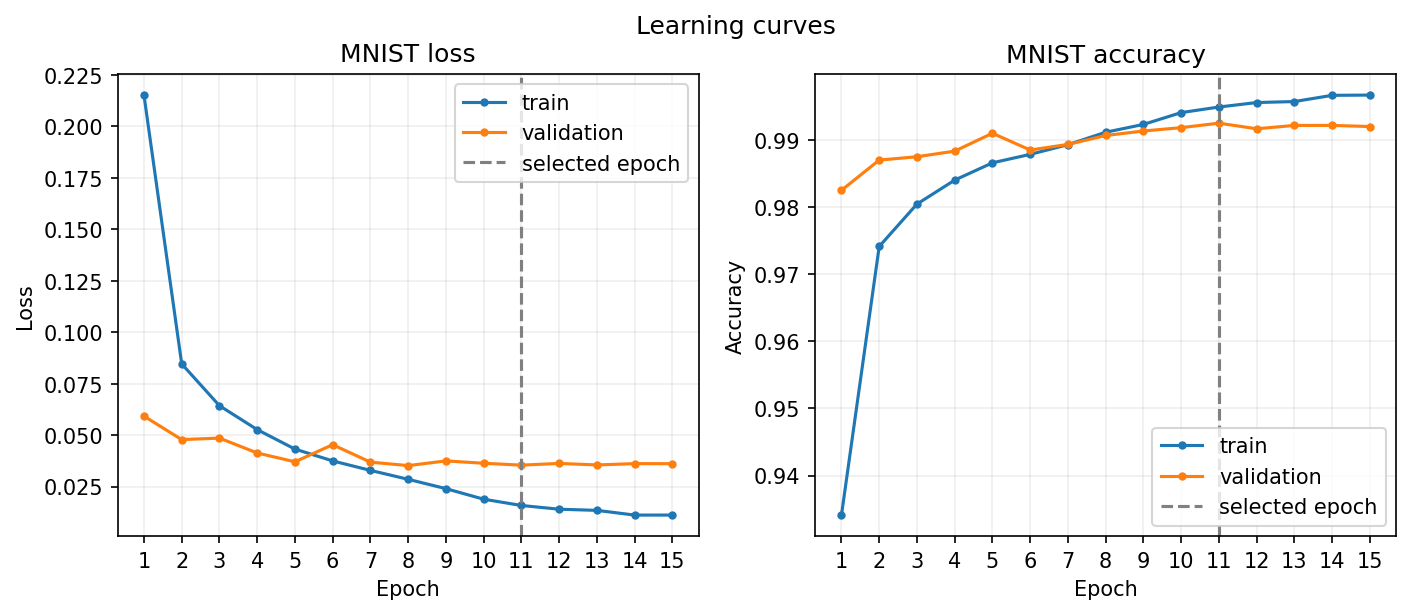

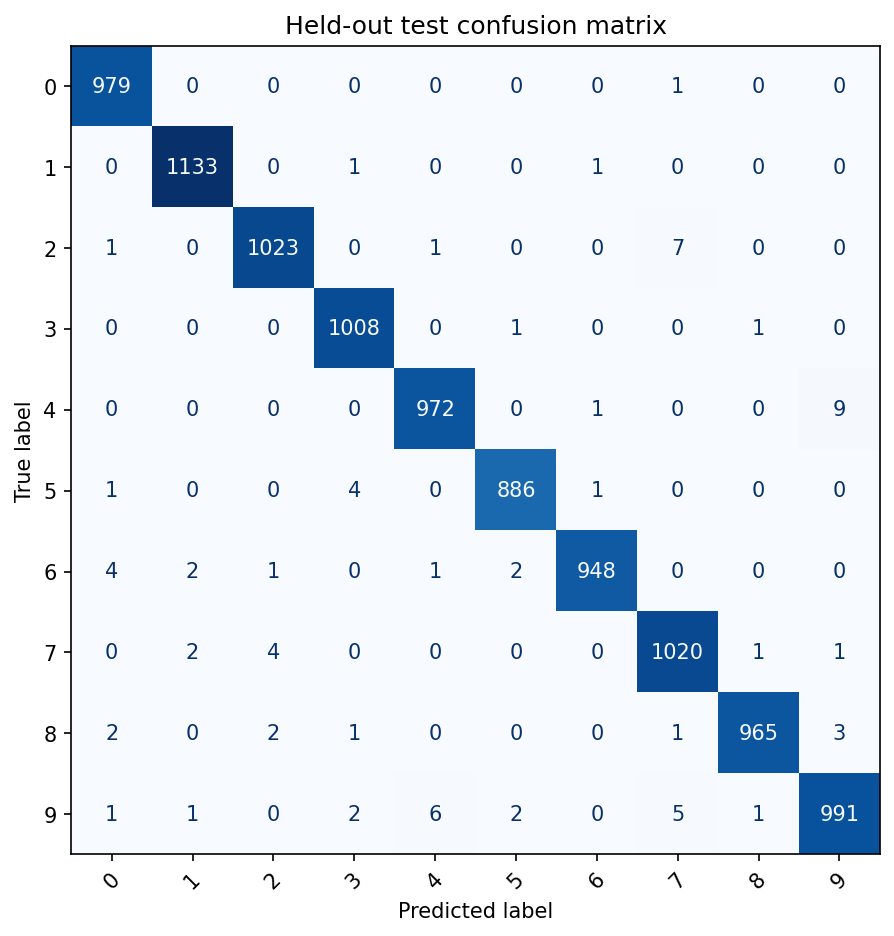

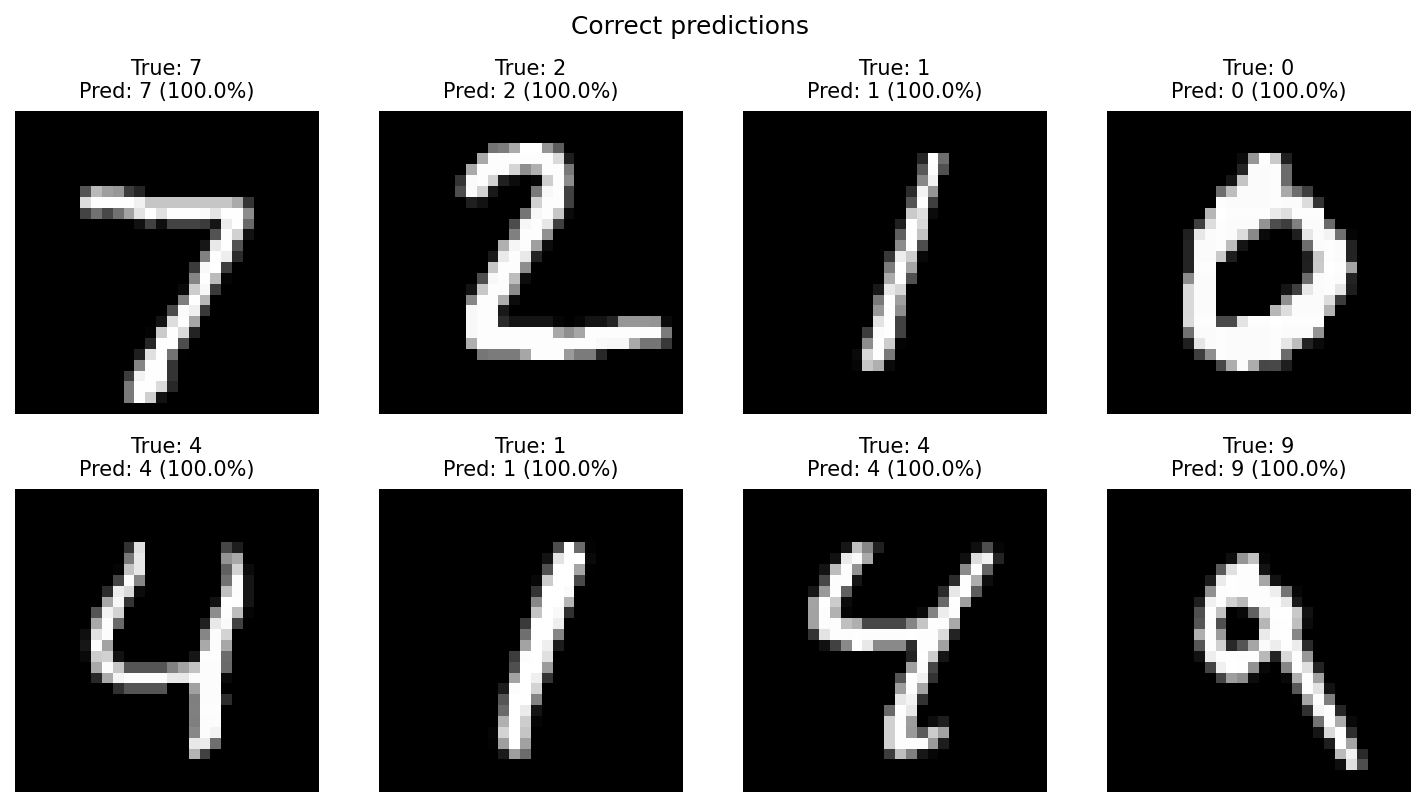

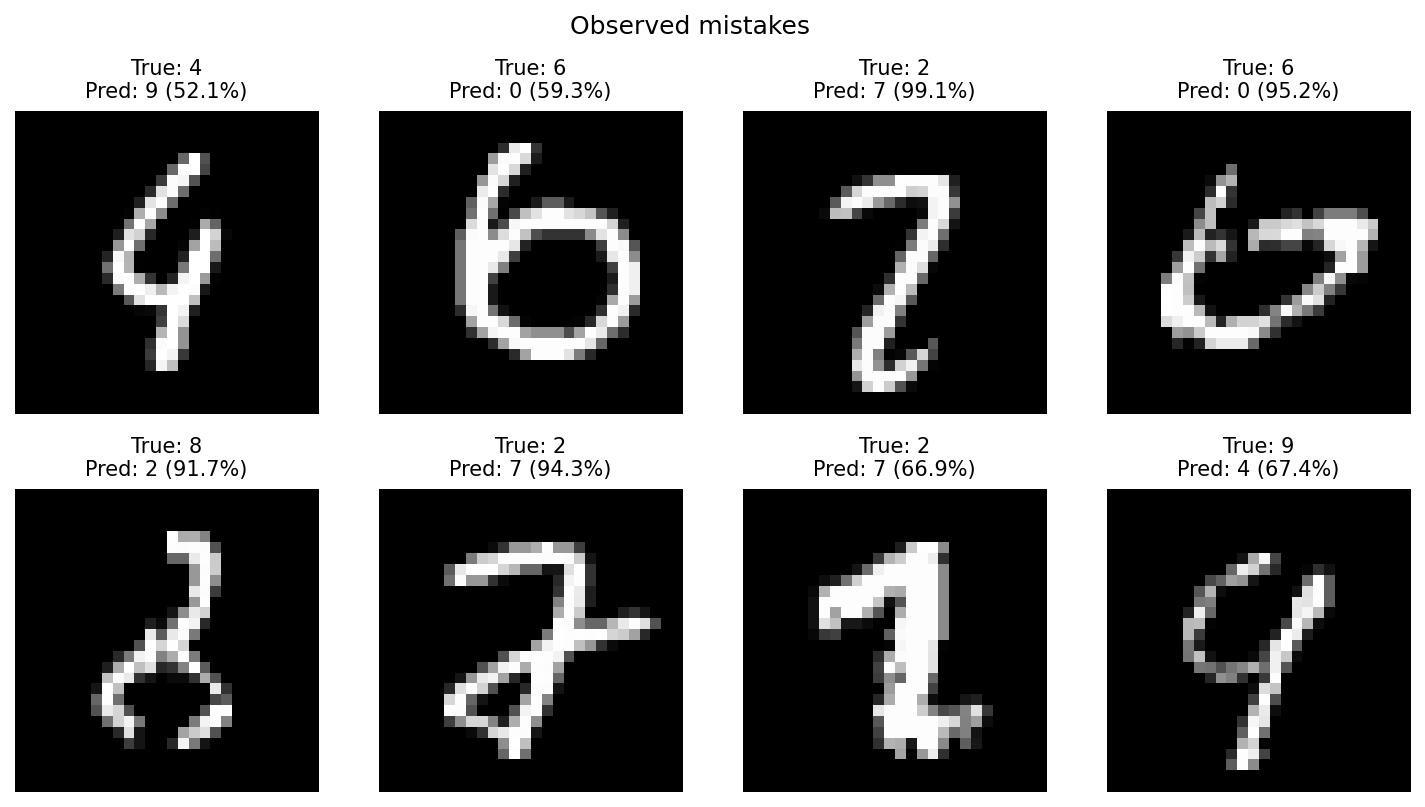

Observed confusion pairs:
- 4 -> 9: 9 images
- 2 -> 7: 7 images
- 9 -> 4: 6 images
- 9 -> 7: 5 images
- 6 -> 0: 4 images

In [15]:
from IPython.display import display, Markdown, Image as DisplayImage

def display_experiment(experiment):
    if experiment is None:
        display(Markdown("**PENDING:** no completed real-data training/evaluation is available."))
        return
    meta, metrics = experiment["metadata"], experiment["evaluation"]
    if meta["smoke"]:
        display(Markdown("**SYNTHETIC SMOKE ONLY — these are not dataset results.**"))
    display(pd.DataFrame([{key: metrics[key] for key in
        ["count", "accuracy", "loss", "macro_precision", "macro_recall", "macro_f1"]}]))
    display(pd.DataFrame(metrics["report"]).T)
    print(f"Parameters: {meta['parameters']:,}; training: {meta['training_seconds']:.1f}s; "
          f"selected epoch: {meta['best_epoch']}; stop: {meta['stop_reason']}")
    print("Training-subset normalization:", meta["mean"], meta["std"])
    if meta.get("telemetry"):
        print(f"Original training device: {meta['runtime']['gpu']}; "
              f"sampled peak temperature: {meta['telemetry']['peak_temperature_c']:.0f} C; "
              f"sampled peak device memory: {meta['telemetry']['peak_device_memory_used_mib']:.0f} MiB")
    for path in experiment["figures"]:
        display(DisplayImage(filename=str(path)))
    display(Markdown("Observed confusion pairs:\n" + observed_errors(metrics, meta["classes"])))

display_experiment(experiments["mnist"])


## 8. CIFAR-10 methodology
VisionNet is an original narrow residual CNN, trained from scratch without pretrained weights. A 32-channel stem feeds three stages at widths 32, 64 and 128, with two residual blocks per stage. Each block contains two 3×3 convolutions and batch normalization; downsampling uses stride 2 with a 1×1 projected shortcut. Global average pooling and dropout (0.25) feed ten logits. There is no ImageNet pretraining or test-time augmentation.

AdamW (learning rate 0.001, weight decay 0.0005) and cosine scheduling provide a simple bounded baseline. Batch size is 64, maximum epochs 50, patience 12, and time budget 115 minutes (plus five minutes reserved for the interrupted preliminary attempt). This is a practical experiment budget, not a promise of 85–90% accuracy. Stronger augmentation, longer schedules or wider models are future validation-only investigations rather than changes made in response to this test set.


## 9. Complete executable CIFAR-10 implementation
`ResidualBlock`, `VisionNet`, data augmentation, optimizer/scheduler, training, evaluation and Grad-CAM are fully implemented above in notebook-local cells. This call runs the distinct CIFAR-10 experiment using those definitions. Its weights, split, curves and cached test predictions are stored independently from DigitNet.


In [16]:
experiments["cifar10"] = run_experiment(
    "cifar10", root=PROJECT_ROOT, experiment_id=EXPERIMENT_ID, config=CONFIGS["cifar10"],
    allow_training=ALLOW_TRAINING, download=DOWNLOAD_DATA, retrain=RETRAIN,
    smoke=SMOKE_TEST, device_preference=DEVICE_PREFERENCE, seed=SEED)


cifar10: loaded trained epoch 49 on cpu; using saved test results, no training or dataset access.


## 10. CIFAR-10 experimental results
The cell reports the selected model on untouched official test images once, or loads predictions for that exact checkpoint. **Completed:** 90.92% test accuracy, loss 0.39882; selected epoch 49; 54.76 minutes training. The Grad-CAM example uses fixed test index zero; its color intensity is relative within that image, not a calibrated importance score.


,count,accuracy,loss,macro_precision,macro_recall,macro_f1
0,10000,0.9092,0.398818,0.909334,0.9092,0.909204


,precision,recall,f1-score,support
airplane,0.914000,0.9140,0.914000,1000.0000
automobile,0.959799,0.9550,0.957393,1000.0000
bird,0.882820,0.8890,0.885899,1000.0000
cat,0.820041,0.8020,0.810920,1000.0000
deer,0.898608,0.9040,0.901296,1000.0000
dog,0.848837,0.8760,0.862205,1000.0000
frog,0.935807,0.9330,0.934402,1000.0000
horse,0.951446,0.9210,0.935976,1000.0000
ship,0.943731,0.9560,0.949826,1000.0000
truck,0.938247,0.9420,0.940120,1000.0000


Parameters: 696,618; training: 3285.8s; selected epoch: 49; stop: epoch_limit
Training-subset normalization: [0.49113735123913904, 0.48211118702345923, 0.4464489876090109] [0.24686913619555195, 0.24343012612619694, 0.26160339391496956]
Original training device: Quadro T1000; sampled peak temperature: 73 C; sampled peak device memory: 619 MiB


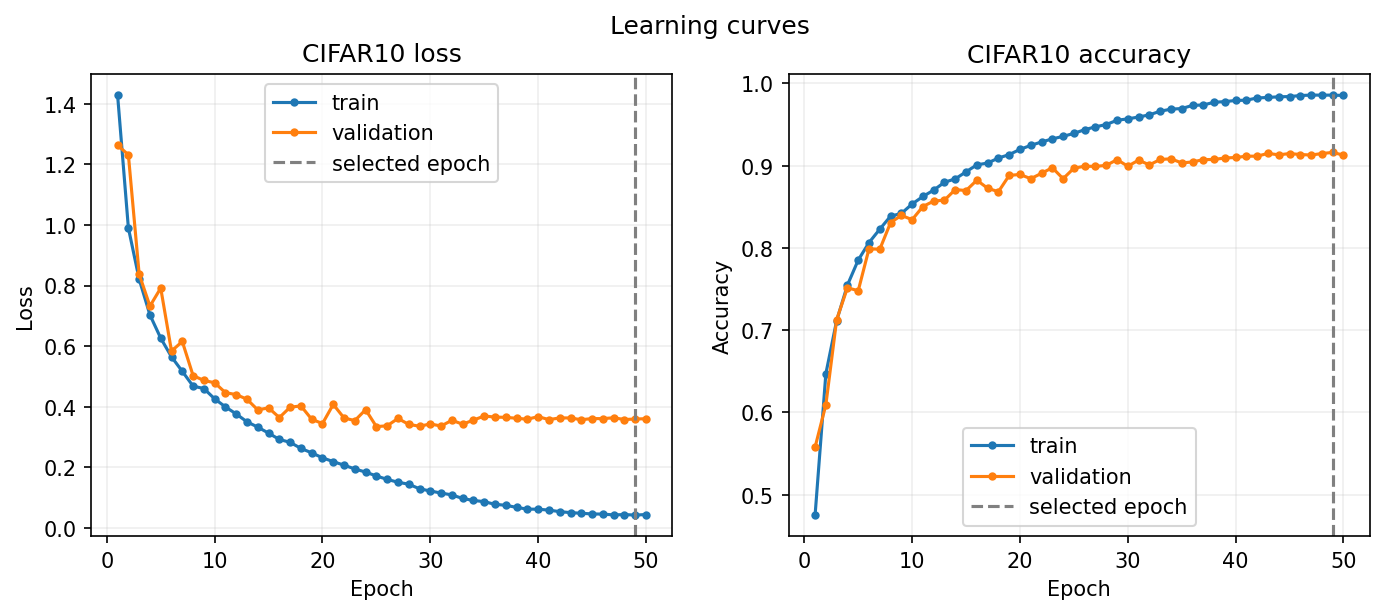

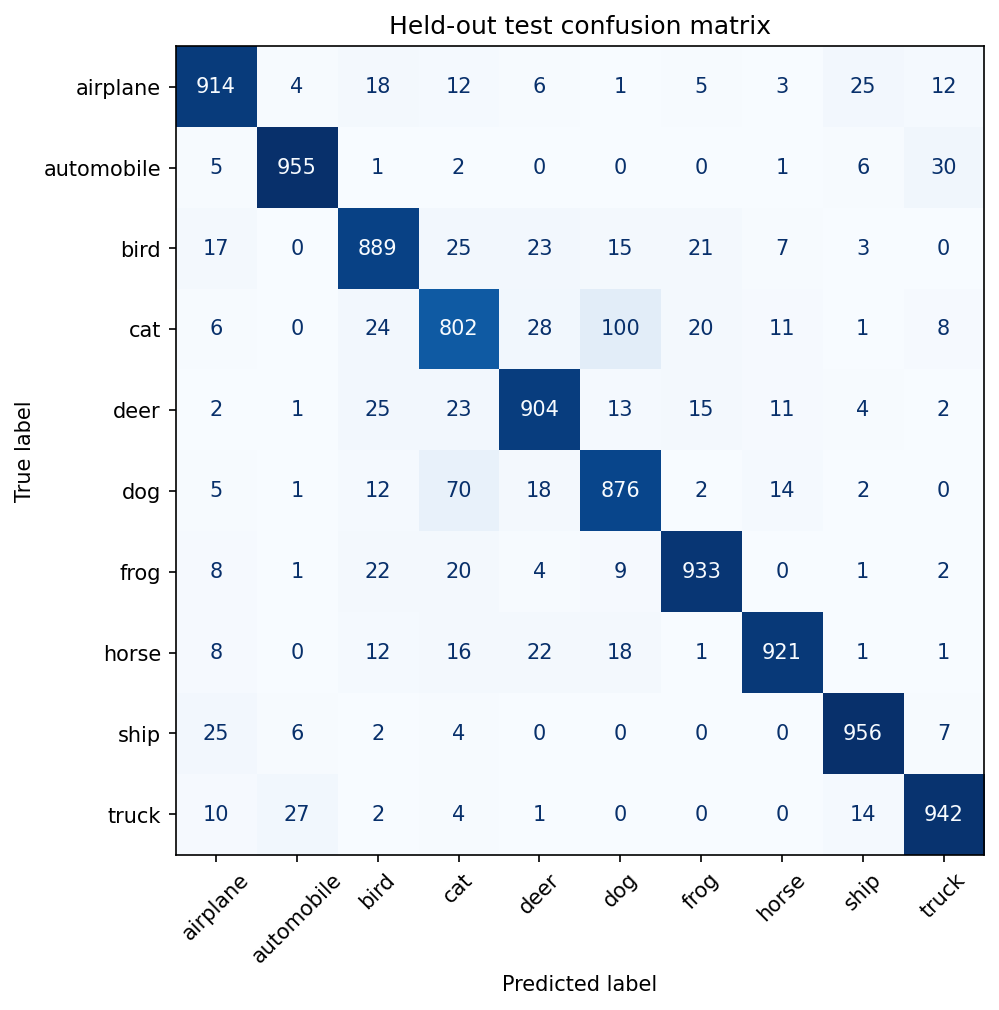

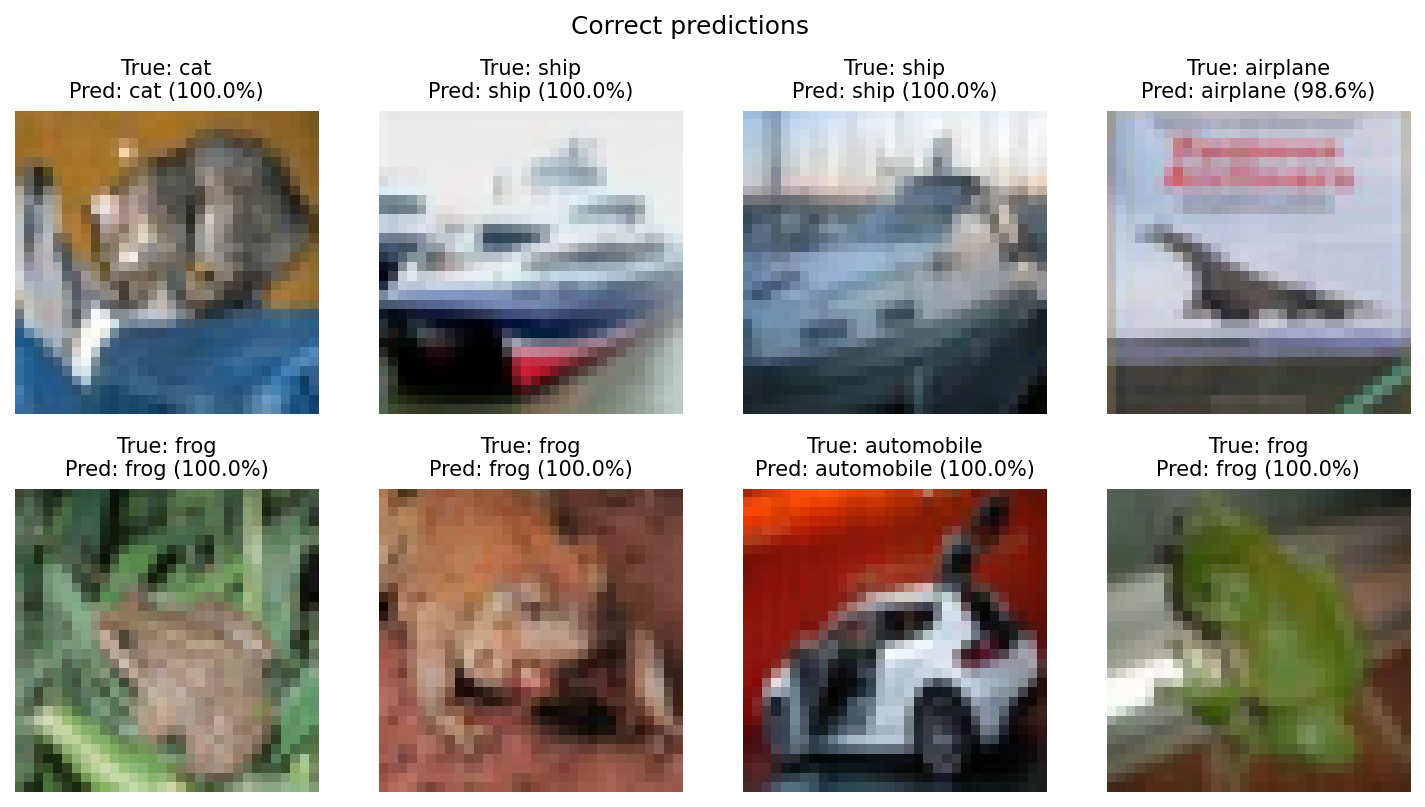

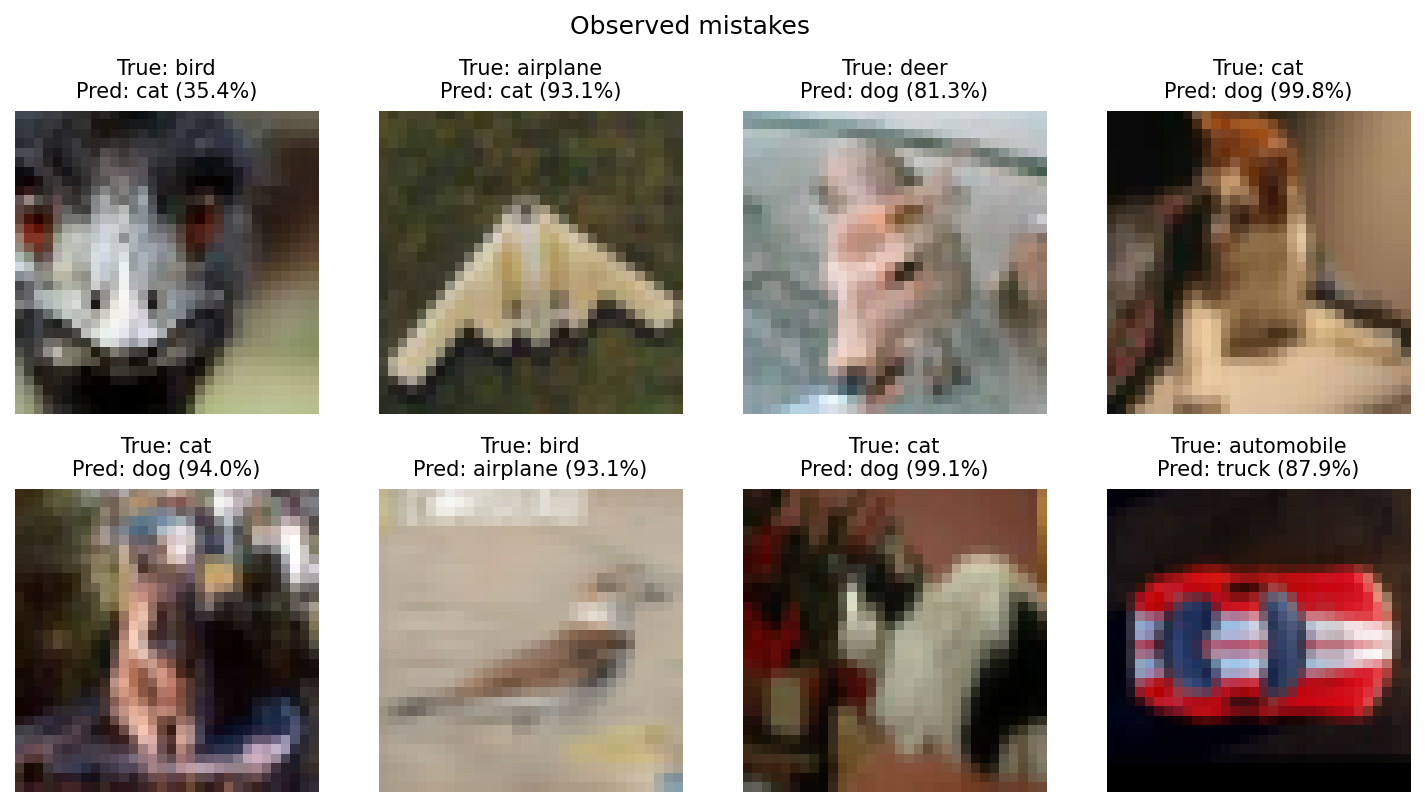

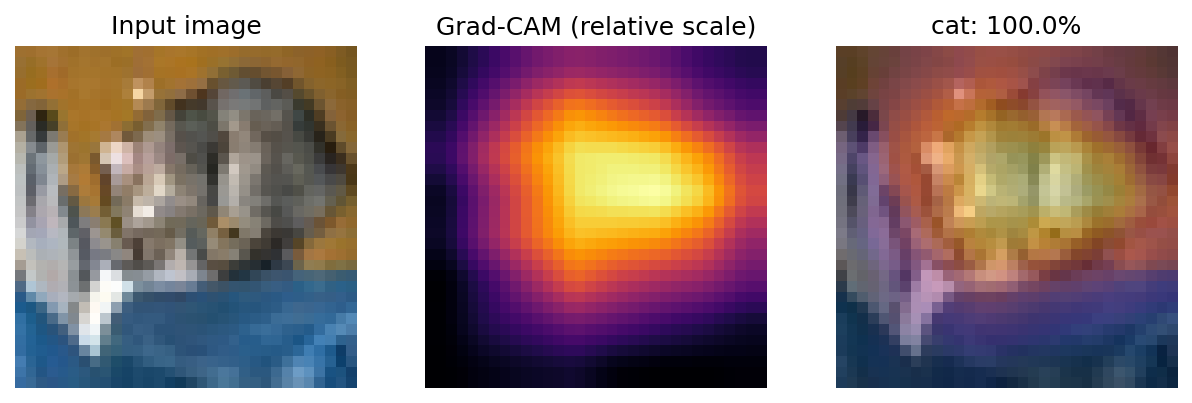

Observed confusion pairs:
- cat -> dog: 100 images
- dog -> cat: 70 images
- automobile -> truck: 30 images
- cat -> deer: 28 images
- truck -> automobile: 27 images

In [17]:
display_experiment(experiments["cifar10"])


## 11. Visualizations, error analysis and prediction demonstrations
Confusion matrices, mistakes and correct examples above derive from the saved test predictions. The listed confusion counts describe actual outcomes. Similar outlines, handwriting ambiguity, low resolution, clutter or pose are **possible hypotheses to inspect in the displayed mistakes**, not established explanations. If results are pending, no empirical mistake pattern can be stated. If no mistakes occur in a small smoke fixture, that says nothing about benchmark performance.

For a digit upload, use a single clearly written digit with a plain background. Processing removes background intensity, handles ink polarity (with manual override), fits a glyph inside 20×20 pixels, pads to 28×28, and centers its intensity centroid. Color uploads are converted to RGB and resized to 32×32. This can remove useful detail. CIFAR-10 recognizes only ten predefined classes and will still assign an unfamiliar image one of those labels. Softmax scores are not calibrated certainty.


In [18]:
"""Image preprocessing, path-based prediction and optional notebook uploads."""
import io
from pathlib import Path

import numpy as np
import torch
from PIL import Image, ImageOps
from torchvision import transforms


def prepare_user_image(source, dataset: str, mean, std, polarity: str = 'auto'):
    """Return normalized CHW tensor and the actual resized image shown to the model."""
    if polarity not in {'auto', 'dark-on-light', 'light-on-dark'}:
        raise ValueError('Unknown polarity.')
    if isinstance(source, Image.Image):
        original = ImageOps.exif_transpose(source).copy()
    else:
        with Image.open(source) as opened:
            original = ImageOps.exif_transpose(opened).copy()
    rgba = original.convert('RGBA')
    background_color = 'white'
    rgba_pixels = np.asarray(rgba)
    if dataset == 'mnist' and np.any(rgba_pixels[..., 3] < 255):
        visible = rgba_pixels[..., 3] > 127
        visible_brightness = rgba_pixels[..., :3][visible].mean() if visible.any() else 0
        if polarity == 'light-on-dark' or (polarity == 'auto' and visible_brightness > 127):
            background_color = 'black'
    background = Image.new('RGBA', rgba.size, background_color)
    background.alpha_composite(rgba)
    image = background.convert('RGB')
    if dataset == 'mnist':
        pixels = np.asarray(image.convert('L'), dtype=np.float32)
        border = np.concatenate([pixels[0], pixels[-1], pixels[:, 0], pixels[:, -1]])
        invert = polarity == 'dark-on-light' or (polarity == 'auto' and np.median(border) > 127)
        if invert:
            pixels = 255 - pixels
        pixels = np.maximum(pixels - np.median(np.concatenate([pixels[0], pixels[-1], pixels[:, 0], pixels[:, -1]])), 0)
        if pixels.max() < 10:
            raise ValueError('No visible digit detected. Use one high-contrast digit on a plain background.')
        pixels = np.uint8(np.clip(pixels / pixels.max() * 255, 0, 255))
        mask = pixels > 40
        yy, xx = np.where(mask)
        glyph = Image.fromarray(pixels).crop((int(xx.min()), int(yy.min()), int(xx.max()) + 1, int(yy.max()) + 1))
        glyph.thumbnail((20, 20), Image.Resampling.LANCZOS)
        image = Image.new('L', (28, 28), 0)
        image.paste(glyph, ((28 - glyph.width) // 2, (28 - glyph.height) // 2))
        # Translate the intensity centroid to the image center without wraparound.
        canvas = np.asarray(image, dtype=np.float64)
        yy, xx = np.indices(canvas.shape)
        dx = int(round(13.5 - (canvas * xx).sum() / canvas.sum()))
        dy = int(round(13.5 - (canvas * yy).sum() / canvas.sum()))
        centered = Image.new('L', (28, 28), 0)
        centered.paste(image, (dx, dy))
        image = centered
    elif dataset == 'cifar10':
        image = image.resize((32, 32), Image.Resampling.BILINEAR)
    else:
        raise ValueError('Dataset must be mnist or cifar10.')
    tensor = transforms.Normalize(mean, std)(transforms.ToTensor()(image))
    return tensor, image


def predict_image(model, source, metadata: dict, device, polarity='auto') -> dict:
    if metadata.get('smoke') or metadata.get('training_status') != 'complete':
        raise ValueError('Predictions require a completed real-data training run.')
    tensor, processed = prepare_user_image(source, metadata['dataset'], metadata['mean'], metadata['std'], polarity)
    model.eval()
    with torch.inference_mode():
        probabilities = model(tensor.unsqueeze(0).to(device)).softmax(1)[0].cpu().numpy()
    order = np.argsort(probabilities)[::-1]
    return {'processed_image': processed, 'tensor': tensor,
            'probabilities': probabilities,
            'top_classes': [(metadata['classes'][i], float(probabilities[i])) for i in order[:3]]}


def predict_file(path, checkpoint, dataset, device='cpu', polarity='auto') -> dict:
    """Non-widget fallback, usable in any Python environment with the dependencies."""
    device = torch.device(device)
    model = make_model(dataset)
    meta = load_checkpoint(Path(checkpoint), model, device, {'dataset': dataset, 'smoke': False})
    return predict_image(model, path, meta, device, polarity)


def prediction_dashboard(experiments: dict, device):
    from IPython.display import display
    try:
        import ipywidgets as widgets
    except ImportError:
        print('ipywidgets is unavailable. Use predict_file(image_path, checkpoint_path, dataset).')
        return None
    available = {name: result for name, result in experiments.items()
                 if result is not None and not result['metadata']['smoke']}
    if not available:
        print('Dashboard pending: train/load a real model first. Path-based fallback: predict_file(...).')
        return None
    choice = widgets.Dropdown(options=list(available), description='Model:')
    polarity = widgets.Dropdown(options=['auto', 'dark-on-light', 'light-on-dark'], description='Digit ink:')
    upload = widgets.FileUpload(accept='.png,.jpg,.jpeg,.bmp,.webp', multiple=False)
    button = widgets.Button(description='Predict image', button_style='primary')
    output = widgets.Output()

    def predict_clicked(_):
        with output:
            output.clear_output(wait=True)
            panel.last_prediction = None
            panel.last_error = None
            if not upload.value:
                print('Choose a single image first.')
                return
            value = next(iter(upload.value.values())) if isinstance(upload.value, dict) else upload.value[0]
            experiment = available[choice.value]
            try:
                prediction = predict_image(experiment['model'], io.BytesIO(bytes(value['content'])),
                                           experiment['metadata'], device, polarity.value)
            except (OSError, ValueError) as error:
                panel.last_error = str(error)
                print(f'Image could not be classified: {error}')
                return
            panel.last_prediction = prediction
            display(prediction['processed_image'].resize((224, 224)))
            for label, probability in prediction['top_classes']:
                print(f'{label}: {probability:.2%}')
            print('Probabilities are model scores, not calibrated certainty.')
            if choice.value == 'cifar10':
                print('CIFAR-10 recognizes only its ten predefined classes; unfamiliar objects still receive one of those labels.')

    button.on_click(predict_clicked)
    panel = widgets.VBox([widgets.HTML('<b>DualVision AI — upload one digit or one CIFAR-10-like object</b>'),
                          choice, polarity, upload, button, output])
    panel.last_prediction = None
    panel.last_error = None
    display(panel)
    return panel


In [19]:
dashboard = prediction_dashboard(experiments, DEVICE)

# Reliable non-interactive fallback after completing training:
# result = predict_file("my_digit.png", PROJECT_ROOT / "checkpoints" / EXPERIMENT_ID / "mnist" / "best.pt", "mnist", DEVICE)
# display(result["processed_image"])
# print(result["top_classes"])
# result = predict_file("my_object.jpg", PROJECT_ROOT / "checkpoints" / EXPERIMENT_ID / "cifar10" / "best.pt", "cifar10", DEVICE)
# print(result["top_classes"])


mnist: real checkpoint inference on cpu; top classes [('7', 0.9999998807907104), ('3', 1.0623627844097427e-07), ('9', 2.4466732639893962e-08)]


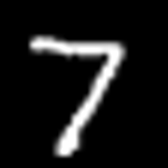

cifar10: real checkpoint inference on cpu; top classes [('cat', 0.9999998807907104), ('dog', 1.2230216839270724e-07), ('frog', 4.811071788353438e-13)]


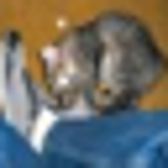

In [20]:
# Fixed official test index 0 for each dataset; included as small demonstration PNGs.
# This runs actual inference on the current device, even when saved report metrics are reused.
for name, experiment in experiments.items():
    if experiment is None or experiment["metadata"]["smoke"]:
        continue
    example = experiment["output_dir"] / "examples" / "test_index_0.png"
    if example.exists():
        prediction = predict_file(example, experiment["checkpoint"], name, DEVICE)
        print(f"{name}: real checkpoint inference on {DEVICE}; top classes {prediction['top_classes']}")
        display(prediction["processed_image"].resize((168, 168)))


## 12. Comparative discussion
MNIST has centered grayscale symbols and limited background variation. CIFAR-10 has color, viewpoint changes, backgrounds and more diverse within-class appearances at only 32×32 pixels. VisionNet therefore uses more feature processing and residual connections. Parameter count, measured training time and macro metrics below summarize each experiment.

**Cross-dataset accuracies measure different tasks and must not be interpreted as a controlled ranking of architectures.** Neither accuracy targets nor synthetic scores belong in the experimental results. A fair architecture comparison would train both architectures on the same dataset with a controlled budget and validation protocol.

### Observations from the completed MNIST experiment

DigitNet classified 9,925 of 10,000 held-out images correctly (99.25%; test cross-entropy 0.02677). Macro precision, recall and F1 were 0.99253, 0.99243 and 0.99247. It trained for 320.85 seconds and completed all 15 planned epochs; validation selected epoch 11. Later training loss continued to fall while validation accuracy stayed close to 99.2%, so the final epoch was not substituted for the selected checkpoint.

The 75 test errors include nine 4-to-9, seven 2-to-7, six 9-to-4, five 9-to-7 and four 6-to-0 mistakes. Digit 9 had the lowest recall, 98.22%. In the first-error panel, some 6-to-0 mistakes have prominent closed loops, and some 2-to-7 mistakes have angular upper strokes. These visible similarities are plausible contributors, not established causal explanations. One displayed 2-to-7 error received a 99.1% softmax score, demonstrating that a high score does not guarantee correctness.

### Observations from the completed CIFAR-10 experiment

VisionNet classified 9,092 of 10,000 held-out images correctly (90.92%; cross-entropy 0.39882). Macro precision, recall and F1 were 0.90933, 0.90920 and 0.90920. Validation selected epoch 49 at 91.62% accuracy; all 50 planned epochs completed, so the stop reason was the epoch limit, not early stopping. The reported cumulative active duration was approximately 3,285.77 seconds (54 minutes 46 seconds), subject to the recovery accounting described below.

There were 908 test errors. Cat-to-dog (100 images) and dog-to-cat (70) were the largest directed confusions. Other common errors included automobile-to-truck (30), cat-to-deer (28) and truck-to-automobile (27). Cat recall was 80.20% and its F1 was 0.81092, the lowest class F1; automobile had the highest F1, 0.95739. The displayed cat/dog mistakes include close-up faces and partial animal views with little spatial detail. Shared animal shapes and the 32-by-32 resolution are plausible contributors, but these observations do not establish why any individual prediction occurred. The first mistake panel also contains a cat classified as dog with a 99.8% score: confidence alone is not a reliability guarantee.

Training loss continued to decrease while validation loss broadly plateaued after the middle of the schedule. This is consistent with increasing fit to training examples and limited further generalization gains. Training and validation use different dropout/augmentation conditions, so their gap is not a controlled measurement of overfitting. The final test accuracy was 0.70 percentage points below the selected validation accuracy; this gap was reported without further tuning on the test set.

The fixed-index Grad-CAM example is a correctly classified cat. Its strongest relative response lies over the central animal region, with lower response on much of the lower blue background. The gradient map passes the independent analytical CAM identity check. Its broad spatial support does not prove that specific eyes, whiskers or other features caused the decision. The displayed 100.0% score is rounded, not guaranteed certainty.

### Measured comparison and practical interpretation

DigitNet used 421,738 parameters and 5 minutes 21 seconds of training; VisionNet used 696,618 parameters and approximately 54 minutes 46 seconds of cumulative active training. MNIST reached 99.25% test accuracy and macro F1 0.99247; CIFAR-10 reached 90.92% and macro F1 0.90920. Both use the same evaluation definitions, but their input distributions, training schedules and tasks differ. These values therefore do not establish that DigitNet is a better architecture. Color objects, backgrounds and varied viewpoints make CIFAR-10 a more varied recognition problem than centered grayscale digits.

The measured experiments meet the requested aspirational accuracy levels without extra test-driven tuning. Device-wide sampled peaks during the reported runs were 70 C / 247 MiB for MNIST and 73 C / 619 MiB for CIFAR-10; these include any concurrent device activity and are distinct from tensor-allocation measurements. Both stayed below the project safety thresholds. The fixed official test-index-zero image for each dataset was correctly predicted through both the CPU widget callback and the path-based fallback (digit 7 and cat respectively). These two demonstrations verify interface operation, not additional benchmark accuracy or generalization to arbitrary uploads.

### Runtime and experimental interruption

The initial CIFAR-10 process terminated externally after three complete epochs, before any test evaluation. No temperature or memory safety stop was logged, and the exact external cause is unknown. Its checkpoint and telemetry were preserved locally. Because no optimizer state was available for exact resumption, the reported CIFAR-10 experiment was restarted from the original seed and initialization. Its cap was reduced to 115 minutes, with five minutes reserved for the interrupted attempt within the approved 120-minute total. The preliminary checkpoint was not a candidate for final model selection. Wall-clock training duration excludes dataset preparation, final test evaluation and report generation.

The replacement process also ended externally after epoch 4, before testing. On 16 October its validation-selected epoch-4 weights were recovered, with fresh AdamW moments and a reseeded random stream; the original cosine epoch schedule continued. This is a documented warm restart of the same training-only experiment, not an exact uninterrupted trajectory. Subsequent epoch snapshots include the full optimizer, scheduler and RNG state. The cumulative duration includes a conservative five-second allowance for unsampled interruption work and excludes the inactive overnight gap. These recovery deviations limit exact reproduction by a simple uninterrupted run of the defaults. The original epoch-4 checkpoint is preserved locally as `recovery_epoch4.pt`.

A later external interruption occurred after epoch 23. That continuation restored the full saved optimizer, cosine schedule and random states rather than resetting them. Completed epochs were not repeated. Logged partial-epoch work and an additional five-second allowance count toward the cumulative training budget, although incomplete-epoch metrics are excluded from the curves. Reported CIFAR-10 duration is therefore an approximate cumulative active runtime, including recovery overhead and conservative allowances; it is not uninterrupted wall-clock elapsed time.



In [21]:
comparison = comparison_table(experiments)
display(comparison)
if all(exp is not None and not exp["metadata"]["smoke"] for exp in experiments.values()):
    for name, exp in experiments.items():
        print(f"Measured {name}: {exp['evaluation']['accuracy']:.2%} accuracy; macro F1 {exp['evaluation']['macro_f1']:.4f}.")
else:
    print("Real cross-dataset results are pending; no empirical accuracy comparison is claimed.")


,dataset,status,parameters,test_accuracy,macro_precision,macro_recall,macro_f1,training_seconds
0,mnist,measured test results,421738,0.9925,0.992531,0.992431,0.992474,320.846011
1,cifar10,measured test results,696618,0.9092,0.909334,0.909200,0.909204,3285.771984


Measured mnist: 99.25% accuracy; macro F1 0.9925.
Measured cifar10: 90.92% accuracy; macro F1 0.9092.


## 13. Limitations and possible improvements
This is a single-seed baseline, not a statistically comprehensive study. Fixed seeds improve repeatability, but exact results can differ across PyTorch versions, hardware and numerical kernels. The runtime record captures versions and deterministic settings. Training time is hardware-dependent and excludes dataset preparation and final evaluation. The wall-clock budget may stop before cosine annealing finishes. If it does, report that fact and the observed scores.

Training metrics are collected with dropout enabled and, for CIFAR-10, random augmentation. Validation metrics use deterministic preprocessing and evaluation mode. Their gap therefore reflects different measurement conditions as well as possible generalization differences.

Uploaded images may differ substantially from the training distribution. Neither model has an unknown class. Grad-CAM is coarse and highlights associations rather than proving causation. Test metrics have sampling uncertainty; repeated seeds and confidence intervals would strengthen conclusions. Future changes should be selected using validation data and a separately planned evaluation protocol. Potential improvements include small digit translations, CIFAR-10 color augmentation, label smoothing, validation-calibrated probabilities and repeated-seed experiments within the hardware budget.


## 14. Conclusion
Measured held-out test accuracy: **DigitNet 99.25%**, **VisionNet 90.92%** (10,000 test images each). Both models were trained from scratch; test scores were not used for selection.

The saved validation-selected weights, measured figures and CPU-executable inference are included in this notebook. The results support the expected difference in task difficulty, while this single-seed cross-dataset study does not isolate architecture quality. No further tuning was performed using test scores.


In [22]:
real_complete = all(exp is not None and not exp["metadata"]["smoke"] for exp in experiments.values())
print("REAL EXPERIMENTS COMPLETE — inspect the measured results above and fill in student details."
      if real_complete else "SUBMISSION INCOMPLETE: real MNIST/CIFAR-10 training, test results and scientific conclusions are pending.")


REAL EXPERIMENTS COMPLETE — inspect the measured results above and fill in student details.


## 15. Reproduction and submission checklist
- Restart the Python 3.12 kernel and run all cells; ensure no errors.
- Confirm actual CUDA tensor verification (or honestly report CPU execution).
- Confirm both official datasets, training-only normalization, disjoint validation indices and separate checkpoints.
- Complete real training and cached final evaluation for both models; synthetic smoke mode is insufficient.
- Confirm curves/metrics come from the same checkpoint-bound artifacts.
- Inspect confusion pairs and mistakes; add observations supported by the actual images.
- Fill in student details and retain executed real outputs in this `.ipynb`.
- Submit **Homework_5_DualVision.ipynb**, not a replacement `.py` file.
- Do not commit datasets, virtual environments or standalone checkpoint files. This notebook intentionally embeds the two compact selected state dictionaries so it can run independently on CPU.

Repository QA commands (not required by this standalone notebook): `python -m pytest`, `python -m scripts.run_experiments --smoke`, and `python -m scripts.smoke_notebook`. The notebook smoke runner copies this notebook into an empty temporary directory, executes all cells against small synthetic fixtures, and checks that no local source modules are needed.


## 16. References
1. Teacher MNIST learning resource: [Elgendy, chapter 3 notebook](https://github.com/moelgendy/deep_learning_for_vision_systems/blob/master/chapter_03/mnist_cnn.ipynb).
2. Teacher CIFAR-10 learning resource: [Elgendy, chapter 4 notebook](https://github.com/moelgendy/deep_learning_for_vision_systems/blob/master/chapter_04/chapter_4_improve_cifar_90_percent.ipynb). These resources inform the task; their code and reported scores are not copied as this project's results.
3. [PyTorch official installation combinations](https://pytorch.org/get-started/previous-versions/) and [PyTorch reproducibility notes](https://docs.pytorch.org/docs/stable/notes/randomness.html).
4. [torchvision MNIST](https://docs.pytorch.org/vision/stable/generated/torchvision.datasets.MNIST.html) and [CIFAR-10](https://docs.pytorch.org/vision/stable/generated/torchvision.datasets.CIFAR10.html).
5. [CIFAR-10 dataset, Krizhevsky](https://www.cs.toronto.edu/~kriz/cifar.html).
6. Selvaraju et al., [Grad-CAM: Visual Explanations from Deep Networks via Gradient-based Localization](https://arxiv.org/abs/1610.02391), ICCV 2017.
7. He et al., [Deep Residual Learning for Image Recognition](https://arxiv.org/abs/1512.03385), CVPR 2016.
8. [scikit-learn classification report](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.classification_report.html).
9. [MIT Open Learning mirror of the unmodified official CIFAR-10 archive](https://huggingface.co/datasets/MIT-OL-AI-D/cifar-10-python). Used after the original host transfer failed; pinned revision `a48007227f9e2cd0af96175f4afb5ac4965e261b`, verified MD5 `c58f30108f718f92721af3b95e74349a`. torchvision still performs the integrity checks.
